In [1]:
import json
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import time
from pathlib import Path
from PIL import Image

In [2]:
# --- Configuration ---
THUMBNAIL_BASE_DIR = Path('/mnt/eight-tb/vine-processed/thumbs')
INPUT_JSONL_FILE = '/mnt/eight-tb/vine-processed/vine_embeddings_plus.jsonl'
N_CLUSTERS = 5000
RANDOM_STATE = 41
FIG_SIZE = (12, 10)
DOT_SIZE = 1


In [3]:
def load_embeddings(jsonl_path):
    """
    Loads embeddings, filenames, and video_id_short from the JSONL file, 
    ensures consistent shape, and mean-pools any (16, D) time-series 
    embeddings to (D,).
    
    Returns: (DataFrame with 'filename', 'embedding', 'video_id_short', 
              list of numpy arrays)
    """
    data = []
    skipped_count = 0
    expected_shape = None
    print(f"Loading data from {jsonl_path}...")
    
    raw_data = []
    try:
        with open(jsonl_path, 'r') as f:
            for line in f:
                if line.strip():
                    item = json.loads(line)
                    raw_data.append({
                        'filename': item['filename'],
                        # 🔑 FIX: Extract the video_id_short field
                        'video_id_short': item.get('video_id_short', None),
                        'whisper_transcript': item.get('whisper_transcript', None),
                        'embedding': np.array(item['embedding'], dtype=np.float32)
                    })
    except (FileNotFoundError, json.JSONDecodeError) as e:
        print(f"Error during file read: {e}")
        return pd.DataFrame(), []

    if not raw_data:
        print("No data found in the input file.")
        return pd.DataFrame(), []

    for item in raw_data:
        current_embedding = item['embedding']
        # filename = item['filename'] # Not needed here, but kept in item
        
        if current_embedding.size == 0:
            skipped_count += 1
            continue

        if current_embedding.ndim == 2 and current_embedding.shape[0] == 16:
            current_embedding = np.mean(current_embedding, axis=0)
            item['embedding'] = current_embedding

        if expected_shape is None:
            expected_shape = current_embedding.shape
            data.append(item)
        elif current_embedding.shape == expected_shape:
            data.append(item)
        else:
            skipped_count += 1
            
    # Note: df now includes 'video_id_short'
    df = pd.DataFrame(data)
    embeddings = list(df['embedding'].values)

    print(f"Successfully loaded {len(embeddings)} consistent embeddings (Skipped {skipped_count} invalid/inconsistent entries).")
    return df, embeddings

In [4]:
import pandas as pd
def display_video_thumbnails(df_or_ids, max_images=25, columns=5, title="Selected Videos"):
    """
    Retrieves and displays thumbnail images for a list of videos.

    Args:
        df_or_ids (pd.DataFrame or list/pd.Series): 
            Either a DataFrame containing 'video_id_short' or a list/Series 
            of 'video_id_short' strings.
        max_images (int): The maximum number of images to display. Defaults to 25.
        columns (int): The number of columns in the display grid. Defaults to 5.
        title (str): The title for the plot. Defaults to "Selected Videos".
    """
    
    # --- 1. Determine the list of short IDs ---
    if isinstance(df_or_ids, pd.DataFrame):
        if 'video_id_short' not in df_or_ids.columns:
            print("❌ Error: DataFrame must contain the 'video_id_short' column.")
            return
        # Use the IDs from the DataFrame (e.g., if you pass df_data[:10])
        short_ids = df_or_ids['video_id_short'].tolist()
        
    elif isinstance(df_or_ids, (list, pd.Series)):
        # Use the list or Series directly (e.g., if you pass short_ids_list)
        short_ids = list(df_or_ids) 
        
    else:
        print("❌ Error: Input must be a DataFrame, list, or pandas Series of IDs.")
        return

    if not short_ids:
        print("📦 Found 0 IDs to display.")
        return


    num_found = len(short_ids)
    print(f"📦 Found {num_found} IDs. Displaying first {min(num_found, max_images)}.")
    
    # Limit the number of IDs to display
    ids_to_display = short_ids[:max_images]
    num_to_display = len(ids_to_display)
    
    # Calculate rows needed for the grid display
    rows = (num_to_display + columns - 1) // columns
    
    # 2. Setup the plot grid
    plt.figure(figsize=(columns * 3, rows * 3))
    plt.suptitle(f"Thumbnails for: {title}", fontsize=16)
    # print(",".join(short_ids)) # Optionally removed this large print

    # 3. Iterate through IDs and display images
    for i, video_id in enumerate(ids_to_display):
        # Construct the full path
        image_path = THUMBNAIL_BASE_DIR / f"{video_id}.png"
        
        plt.subplot(rows, columns, i + 1)
        
        # Determine the ID string to display in the title
        displayed_id = video_id            
        try:
            # Load and display the image
            img = Image.open(image_path)
            plt.imshow(img)

            # Use the possibly censored ID for the title
            plt.title(f"{displayed_id}", fontsize=8) 
            plt.axis('off') # Hide axis ticks and labels
            
        except FileNotFoundError:
            plt.title("Missing", fontsize=8, color='red')
            plt.text(0.5, 0.5, "Image Not Found", ha='center', va='center', color='red')
            plt.axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.96]) # Adjust layout
    plt.show()

In [5]:
df_data, embeddings_list = load_embeddings(INPUT_JSONL_FILE)

Loading data from /mnt/eight-tb/vine-processed/vine_embeddings_plus.jsonl...
Successfully loaded 28339 consistent embeddings (Skipped 0 invalid/inconsistent entries).


In [6]:
print(df_data[:10])

                                            filename video_id_short  \
0  20130626125209_182352F6-CFF3-497C-9891-8FF7D18...     182352F6-C   
1  20130627194331_18C3F6CB-6E8C-4DD1-A245-CCA4CF2...     18C3F6CB-6   
2  20130628013622_14CF3EAD-D4F8-4174-885A-27A2D49...     14CF3EAD-D   
3  20130628211747_18112C4B-742F-4745-ACB1-C76F89A...     18112C4B-7   
4  20130702110757_0AC9933B-F979-4A43-BB29-89C0C05...     0AC9933B-F   
5  20130704074227_1A217B7F-B00C-4DDC-8DA3-7A222B4...     1A217B7F-B   
6  20130710000252_09A000E490966477263552032768_1b...     09A000E490   
7  20130710011214_142EA383-AA6B-4571-8CD1-3E64FE1...     142EA383-A   
8  20130716094132_027B6A7668966115677821898752_14...     027B6A7668   
9  20130718150344_18912F87-C221-441B-911B-5C2079F...     18912F87-C   

                                  whisper_transcript  \
0          All DOGROUND... ALL DOGROUND... Call ohmd   
1                                        Baby, Baby!   
2  How are you? Great Bob! We're all in a little .

                                            filename video_id_short  \
0  20130626125209_182352F6-CFF3-497C-9891-8FF7D18...     182352F6-C   
1  20130627194331_18C3F6CB-6E8C-4DD1-A245-CCA4CF2...     18C3F6CB-6   
2  20130628013622_14CF3EAD-D4F8-4174-885A-27A2D49...     14CF3EAD-D   
3  20130628211747_18112C4B-742F-4745-ACB1-C76F89A...     18112C4B-7   
4  20130702110757_0AC9933B-F979-4A43-BB29-89C0C05...     0AC9933B-F   
5  20130704074227_1A217B7F-B00C-4DDC-8DA3-7A222B4...     1A217B7F-B   
6  20130710000252_09A000E490966477263552032768_1b...     09A000E490   
7  20130710011214_142EA383-AA6B-4571-8CD1-3E64FE1...     142EA383-A   
8  20130716094132_027B6A7668966115677821898752_14...     027B6A7668   
9  20130718150344_18912F87-C221-441B-911B-5C2079F...     18912F87-C   

                                  whisper_transcript  \
0          All DOGROUND... ALL DOGROUND... Call ohmd   
1                                        Baby, Baby!   
2  How are you? Great Bob! We're all in a little .

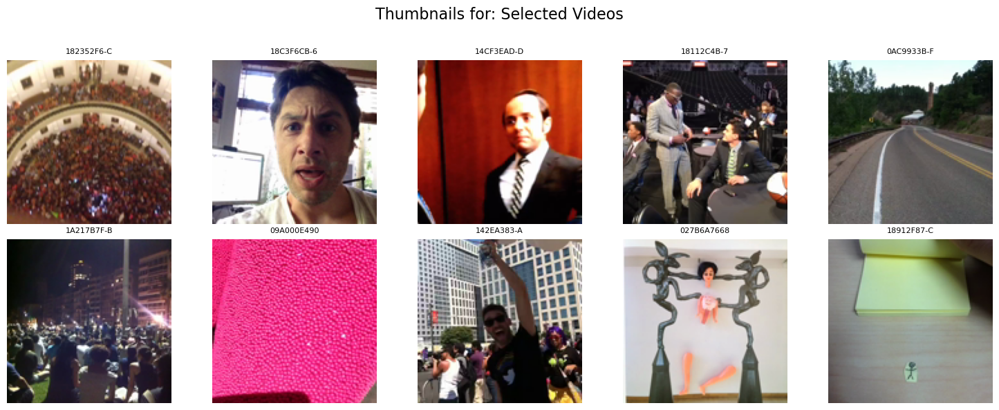

In [7]:
print(df_data[:10])
display_video_thumbnails(df_data[:10])

In [8]:
from scipy.spatial.distance import cdist


def generate_nn_cluster(df_data, search_video_id, N_neighbors=25):
    """
    Finds the N closest neighbors in embedding space to a specified video ID
    and returns a DataFrame containing only those neighbors, ordered by closeness.

    Args:
        df_data (pd.DataFrame): DataFrame containing 'embedding' and 'video_id_short'.
        search_video_id (str): The 'video_id_short' of the seed video.
        N_neighbors (int): The number of closest videos to retrieve.

    Returns:
        pd.DataFrame: A DataFrame of the N closest neighbors, ordered by distance,
                      with a temporary 'cluster' ID for plotting functions.
    """
    if 'embedding' not in df_data.columns or 'video_id_short' not in df_data.columns:
        print("❌ Error: DataFrame must contain 'embedding' and 'video_id_short' columns.")
        return pd.DataFrame()

    # Find the embedding of the seed video
    search_row = df_data[df_data['video_id_short'] == search_video_id]
    
    if search_row.empty:
        print(f"❌ Error: Search video ID '{search_video_id}' not found in DataFrame.")
        return pd.DataFrame()

    # Convert all embeddings to a single matrix (X)
    X_embeddings = np.stack(df_data['embedding'].values)
    # The embedding for the search video (vector q)
    q_embedding = np.stack(search_row['embedding'].values)

    # Calculate the Euclidean distance (L2 norm) between the seed embedding (q) 
    # and every other embedding (X). cdist returns an array of shape (1, N).
    # We use metric='cosine' as it's often better for high-dimensional embeddings, 
    # but 'euclidean' (L2) is also common. Let's use 'euclidean' for simplicity here.
    distances = cdist(q_embedding, X_embeddings, metric='euclidean').flatten()

    # Create a Series with distances and the original DataFrame index
    distance_series = pd.Series(distances, index=df_data.index)

    # Get the indices of the N smallest distances (nearest neighbors)
    # The first one (distance=0) should be the search video itself.
    nearest_indices = distance_series.nsmallest(N_neighbors).index

    # Create the neighbor list, ordered by distance
    nn_df = df_data.loc[nearest_indices].copy()

    # 🔑 CRITICAL: Assign a temporary, unique 'cluster' ID (e.g., 9999) 
    # so the image generator function can filter correctly.
    nn_df['cluster'] = 9999 

    # Add distance column and sort explicitly
    nn_df['distance'] = distance_series.loc[nearest_indices]
    nn_df = nn_df.sort_values(by='distance')
    
    print(f"✅ Found {len(nn_df)} nearest neighbors for {search_video_id}.")
    return nn_df

In [9]:
madmen_clip = "14CF3EAD-D"
mmdf = generate_nn_cluster(df_data,madmen_clip)

✅ Found 25 nearest neighbors for 14CF3EAD-D.


📦 Found 25 IDs. Displaying first 25.


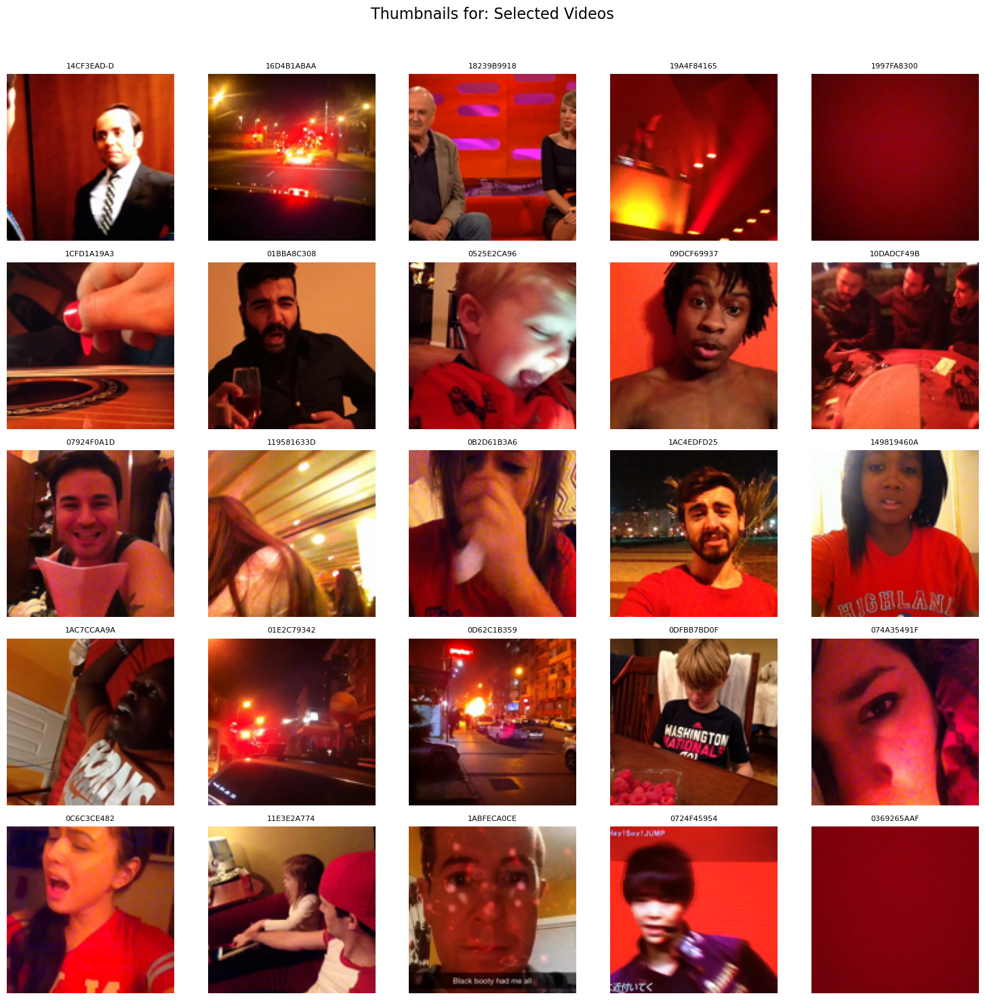

In [10]:
display_video_thumbnails(mmdf)

✅ Found 25 nearest neighbors for 09A000E490.
📦 Found 25 IDs. Displaying first 25.


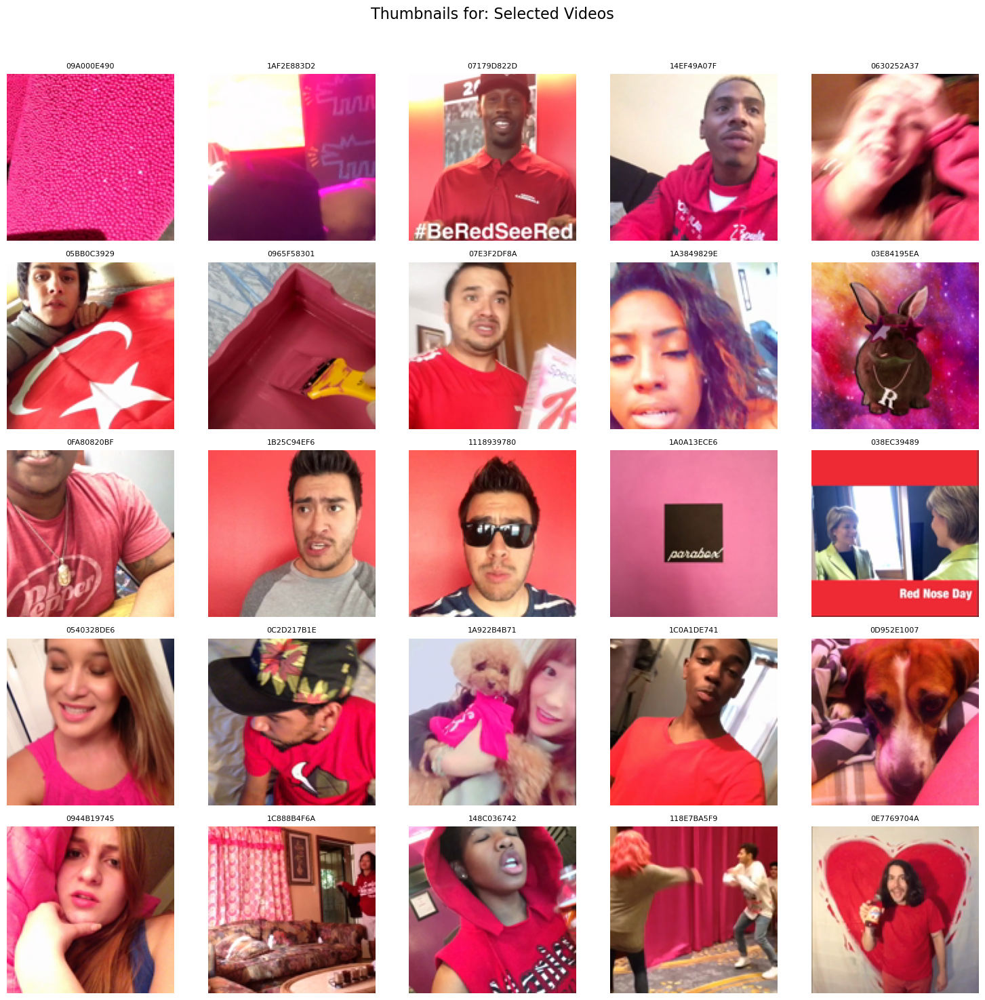

In [11]:
dfnn2 = generate_nn_cluster(df_data,"09A000E490")
display_video_thumbnails(dfnn2)

In [12]:
dfnn2

,filename,video_id_short,whisper_transcript,embedding,cluster,distance
6,20130710000252_09A000E490966477263552032768_1b...,09A000E490,Any current ?,"[-0.023899205, 0.041531604, 0.040510483, 0.022...",9999,0.000000
13511,20150731035854_1AF2E883D21133477726251282432_2...,1AF2E883D2,I'M A BIRTHER! I'M A BIRTHER! I'M A BIRTHER!,"[-0.02130249, 0.039025087, 0.039087884, 0.0201...",9999,0.074881
22461,20160403060709_07179D822D1322018095744827392_5...,07179D822D,"Hey, what's up, Bird Ganger here with Channel ...","[-0.0184477, 0.03453669, 0.050963465, 0.010559...",9999,0.107201
21459,20160221084834_14EF49A07F1162860378942754816_3...,14EF49A07F,"You know you can't fight, you see them here tr...","[-0.020822246, 0.035671663, 0.046124976, 0.018...",9999,0.119915
6113,20140607070905_0630252A371010388024846069760_1...,0630252A37,Hey everyone in my school is a two-faced bitch...,"[-0.021764662, 0.033561192, 0.046240907, 0.014...",9999,0.121153
8377,20141025232717_05BB0C39291006941221144465408_1...,05BB0C3929,None,"[-0.015464476, 0.03378922, 0.04662382, 0.00839...",9999,0.122733
9858,20141205144412_0965F583011085634122711695360_1...,0965F58301,None,"[-0.022446388, 0.040983945, 0.040815417, 0.019...",9999,0.126985
7536,20140922165905_07E3F2DF8A1125871506761633792_2...,07E3F2DF8A,None,"[-0.018307956, 0.034856405, 0.04636374, 0.0094...",9999,0.127339
18543,20151014134914_1A3849829E1241236877110378496_3...,1A3849829E,"I'm feeling okay. Oh, you have a pretty good day.","[-0.019988611, 0.033455934, 0.05117452, 0.0164...",9999,0.130680
18761,20151022182156_03E84195EA1242845336344133632_3...,03E84195EA,We are sensitive to Yumetu We will live only да,"[-0.026695702, 0.04495003, 0.026507331, 0.0290...",9999,0.131198


# Helpful Functions### 
Grid draw for thumbnail IDs DONE
### ffmpeg-based video integration: DONE.### 
Get all words for IDs (from transcript ).# 

Possible Techniqu### es:
Nearest neig DONEh### bors
Linear weighted average between p### oints
K-means clustering (with a###  peek)
tsne (have not tried t (kind of like PCA)hi### s yet).
Small-batch binary classification (e.g. from k means samples).


✅ Found 25 nearest neighbors for 0D952E1007.
📦 Found 25 IDs. Displaying first 25.


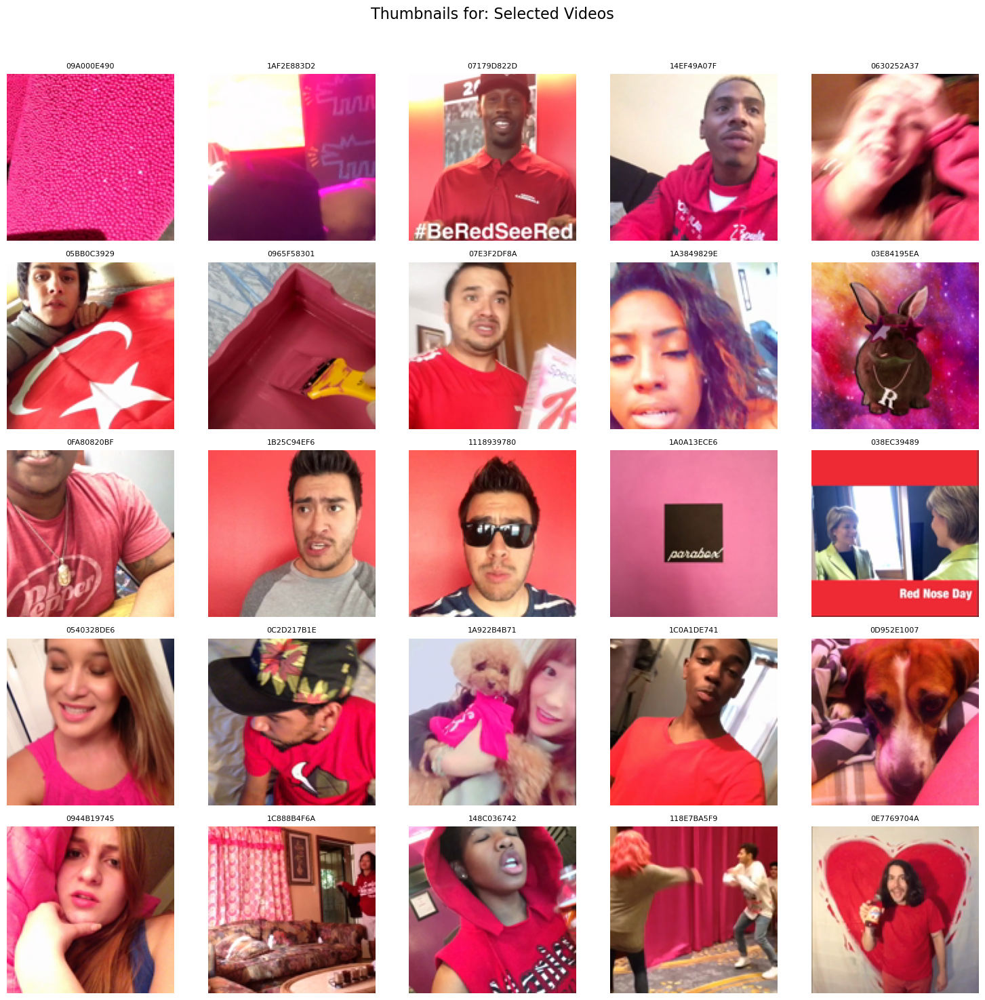

In [13]:
ok_batch = generate_nn_cluster(df_data,"0D952E1007")
display_video_thumbnails(dfnn2)

In [14]:
"""Please make a function that generates a string that I can give to
FFMPEG to stitch together anywhere from 10 to 50 videos. Each of these
videos will be in the same folder (this folder will be given as an absolute folder.
I want the params to be a list of video IDs and an output type, and you can do the rest.
We are using linux (ubuntu server). I want to be able to pass either a list of strings of IDs
or a df like the example I give you.

Example filepath:
/mnt/eight-tb/vine-processed/00E0D97D61.thumb.mp4

Example df:
0  20130626125209_182352F6-CFF3-497C-9891-8FF7D18...     182352F6-C   
1  20130627194331_18C3F6CB-6E8C-4DD1-A245-CCA4CF2...     18C3F6CB-6   
2  20130628013622_14CF3EAD-D4F8-4174-885A-27A2D49...     14CF3EAD-D   
3  20130628211747_18112C4B-742F-4745-ACB1-C76F89A...     18112C4B-7   
4  20130702110757_0AC9933B-F979-4A43-BB29-89C0C05...     0AC9933B-F   
5  20130704074227_1A217B7F-B00C-4DDC-8DA3-7A222B4...     1A217B7F-B   
...
"""


import os
import pandas as pd
from typing import List, Union

def generate_ffmpeg_concat_command(
    video_input: Union[List[str], pd.DataFrame], 
    output_filename: str,
    base_folder_path: str = "/mnt/eight-tb/vine-processed",
    id_column: str = "video_id", # Use if passing a DataFrame
    file_extension: str = ".thumb.mp4"
) -> str:
    """
    Generates an FFmpeg command string using the concat demuxer to stitch videos.

    Args:
        video_input: A list of video IDs (strings) OR a pandas DataFrame 
                     containing a column of video IDs.
        output_filename: The desired name for the stitched output file 
                         (e.g., "stitched_reel.mp4").
        base_folder_path: The absolute path to the directory containing 
                          the video files. Defaults to the example given.
        id_column: The name of the column containing the video IDs if a 
                   DataFrame is provided. Defaults to "video_id".
        file_extension: The common extension/suffix for the video files.
                        Defaults to the example given.

    Returns:
        The complete FFmpeg command string.
    """
    
    # 1. Standardize Input to a List of IDs
    if isinstance(video_input, pd.DataFrame):
        if id_column not in video_input.columns:
            raise ValueError(f"DataFrame must contain a column named '{id_column}'.")
        video_ids = video_input[id_column].astype(str).tolist()
    elif isinstance(video_input, list):
        video_ids = [str(x) for x in video_input]
    else:
        raise TypeError("Input must be a list of IDs or a pandas DataFrame.")
    
    if not (10 <= len(video_ids) <= 50):
        print(f"Warning: Number of videos is {len(video_ids)}, which is outside the suggested range (10-50).")
        
    # 2. Generate Concat List File Content
    # We use os.path.join for robust path construction and single quotes 
    # for file paths, as required by the concat demuxer.
    list_content = ""
    for video_id in video_ids:
        # Example full path: /mnt/eight-tb/vine-processed/00E0D97D61.thumb.mp4
        # Note: The example ID '00E0D97D61' is already the full file name before the extension
        full_filename = video_id + file_extension
        full_filepath = os.path.join(base_folder_path, full_filename)
        list_content += f"file '{full_filepath}'\n"

    # 3. Create the FFmpeg Command using Process Substitution
    # We use process substitution (<(command)) in the final command, which is a 
    # Linux feature that allows the list content to be passed without creating 
    # a temporary file on disk. This is cleaner and safer.
    
    # Escape single quotes in the list_content for the shell, 
    # then embed it into the command using an escaped process substitution.
    escaped_list_content = list_content.replace("'", "'\\''")
    
    # The final command string
    ffmpeg_command = (
        f"ffmpeg -f concat -safe 0 -i <(echo $'{escaped_list_content}') "
        f"-c copy {output_filename}"
    )
    
    # Note: If running this from a Python subprocess, you might need to run it 
    # with `shell=True` due to the process substitution syntax.
    
    return ffmpeg_command

base_path = "/mnt/eight-tb/vine-processed/vidthumbs" # Replace with your actual path
sample_ids = [
    '00E0D97D61', # Example ID
    '182352F6-C', 
    '18C3F6CB-6', 
    '14CF3EAD-D', 
    '18112C4B-7', 
]
sample_ids = list(ok_batch['video_id_short'])
output = "final_video.mp4"

# Generate the command for a list of IDs
command_list = generate_ffmpeg_concat_command(
    video_input=sample_ids, 
    output_filename=output, 
    base_folder_path=base_path
)

print("--- Generated FFmpeg Command ---")
print(command_list)

--- Generated FFmpeg Command ---
ffmpeg -f concat -safe 0 -i <(echo $'file '\''/mnt/eight-tb/vine-processed/vidthumbs/0D952E1007.thumb.mp4'\''
file '\''/mnt/eight-tb/vine-processed/vidthumbs/06356E445C.thumb.mp4'\''
file '\''/mnt/eight-tb/vine-processed/vidthumbs/1B25C94EF6.thumb.mp4'\''
file '\''/mnt/eight-tb/vine-processed/vidthumbs/05462A6CD5.thumb.mp4'\''
file '\''/mnt/eight-tb/vine-processed/vidthumbs/0699E2702F.thumb.mp4'\''
file '\''/mnt/eight-tb/vine-processed/vidthumbs/0540328DE6.thumb.mp4'\''
file '\''/mnt/eight-tb/vine-processed/vidthumbs/07179D822D.thumb.mp4'\''
file '\''/mnt/eight-tb/vine-processed/vidthumbs/07E3F2DF8A.thumb.mp4'\''
file '\''/mnt/eight-tb/vine-processed/vidthumbs/1C0A1DE741.thumb.mp4'\''
file '\''/mnt/eight-tb/vine-processed/vidthumbs/05BB0C3929.thumb.mp4'\''
file '\''/mnt/eight-tb/vine-processed/vidthumbs/0944B19745.thumb.mp4'\''
file '\''/mnt/eight-tb/vine-processed/vidthumbs/0CFAE880A0.thumb.mp4'\''
file '\''/mnt/eight-tb/vine-processed/vidthumbs/145D5F

In [15]:
# get all the transcripts
ok_batch['whisper_transcript']

1832     Buh-Buh, Buh-Buh. Let me take a picture of you...
10281                                                 None
27469    Okay, what the hell so much is Brian Sylvach h...
15522                                                     
11912                                                 None
22178    A little word of advice, don't tell me to calm...
22461    Hey, what's up, Bird Ganger here with Channel ...
7536                                                  None
21690    Alright guys, we're gonna do a group project t...
8377                                                  None
10363                                                 None
16167    There is something no longer under water. Scre...
22503                                                 None
9101                                                  None
25781    I figured out the perfect way to ask them on a...
9030                                                  None
23521    I can't believe you! I did something a Snapcha.

1C83BEA53E ************************************************************
✅ Found 25 nearest neighbors for 1C83BEA53E.
['Okay, calm down, Betty. Good thing, come to those who wait less.', "Don't you wish a golden bus hot like me?", 'Ah music. Ah, cheese.', 'Touching uses its shoulders and its upper body so well, it is an excellent time. Wow!', 'Maryland gets the block shot out of Clarksville, Maryland gets the block shot.', None, 'They transfer to the ball on the floor. Now, I board a ball! Steered on a dunk.', 'Maybe we need to get Castle Men back?', 'Hey, bro, is that my hat? What? You come here too. There we go.', "I'm a beautiful boy, I'm a great gentleman, I'm a great gentleman, I'm a great gentleman, I'm a great gentleman", "The Thunder out of timeouts, Blasperook spotting up inside. He's got it, he's got it.", None, 'On the default', "If your milk goes style, what'd you do with it? You don't put it back in the freezer, do you?", "Hey, I seen the red street. No, there's nothing the

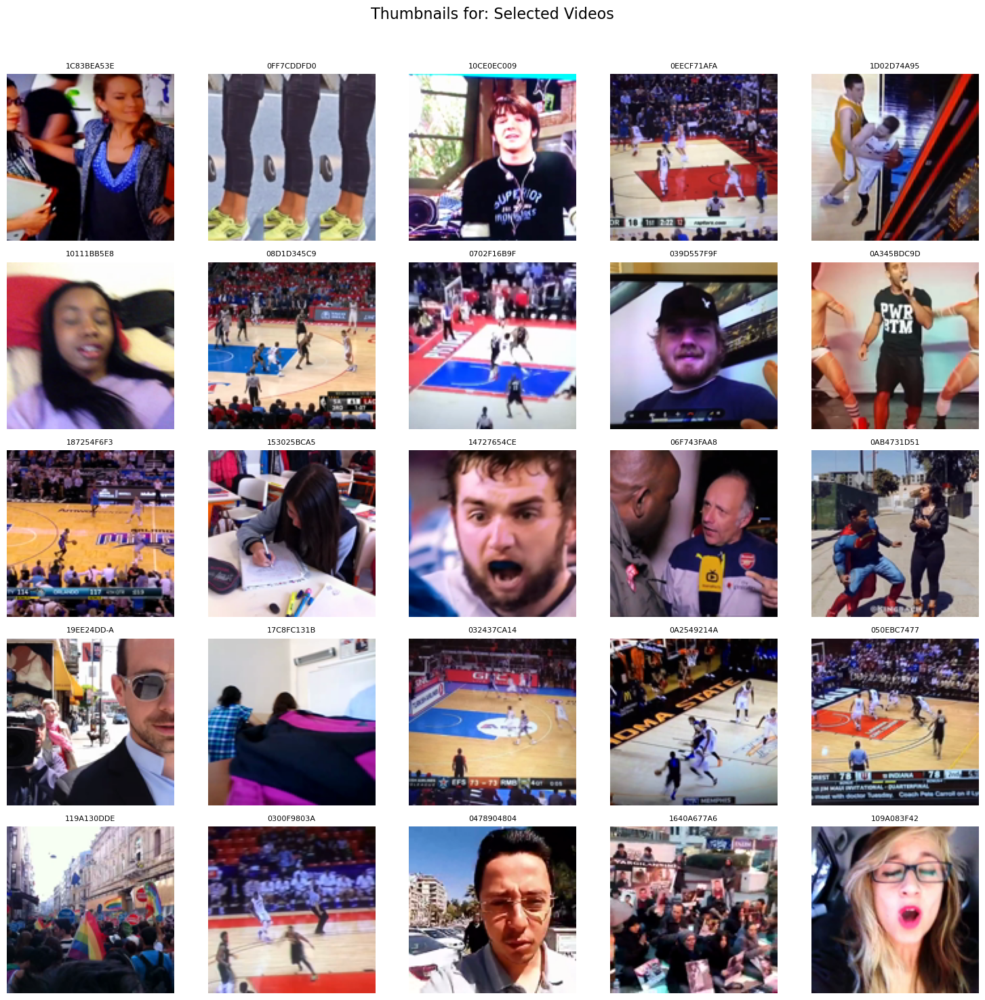

15B1CCF689 ************************************************************
✅ Found 25 nearest neighbors for 15B1CCF689.
['', 'This is Sparta! Sparta! Sparta!', 'This is happening. Finally, to the man in crime, somebody fired away. And then he got standing on his palm, he got under his jargon. He was hinten diz- It was arresting him for advice. Then he did.', None, None, '', "I'm going to be a jack of the world! I'm going to be a jack of the world! I'm going to be a jack of the world!", "And the helicopter is on info, it was just wrong, so no. Wait, I'm going to put the help and the scene was doing it.", None, None, 'Then in the historicalies fouls, Metroetch, Procute', None, None, None, '', 'brute force amnesty...! THIS is fat flannel, Nerio di Santolig一直 fr Area', None, None, None, 'A What?', 'Motricraising Lewis Out from the Bay of Brazil. He Bits there first.валagues.', None, None, None, None]
📦 Found 25 IDs. Displaying first 25.


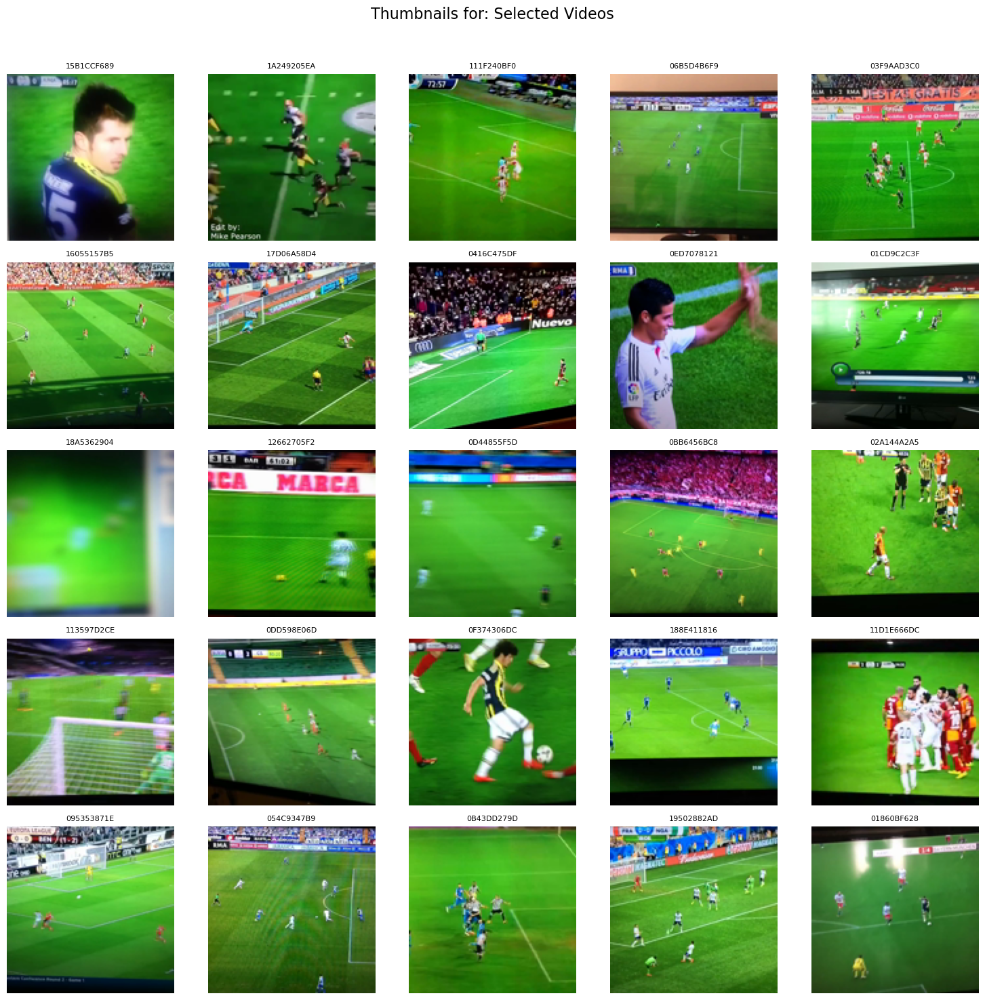

0E24306843 ************************************************************
✅ Found 25 nearest neighbors for 0E24306843.
["I love you, I miss you so much too. No, you can't have your house key back.", "Dude she's a honger, dude. No, no. 2 plus 2 equals 4, so... Oh, bitch! Oh, no! You're the idiot, bitch!", "When you're in study, all I need is to want to scream! Sometimes I just don't care!", None, 'He could be who you are, a fox sake A world, cause real girls in cake', 'Thank you. Ha ha ha ha ha. Ha ha ha ha ha ha ha ha.', "Yo, what's just me and my Jack Russell Terry? You got a good flow and we breaking down barriers doesn't do much But sit back and share with you, take me good care of you Jack Russell Terry", None, "You guys make it through my sub! She's gone!", None, "I'm Jerry Ray's Watchtower Access", 'How many more VERY FECULO-THERF almost true with a predictable AWESOME, IBISAF30', 'When the days are...', "I'm holding you closer than I was, you and I ever", None, "Come on girls, act

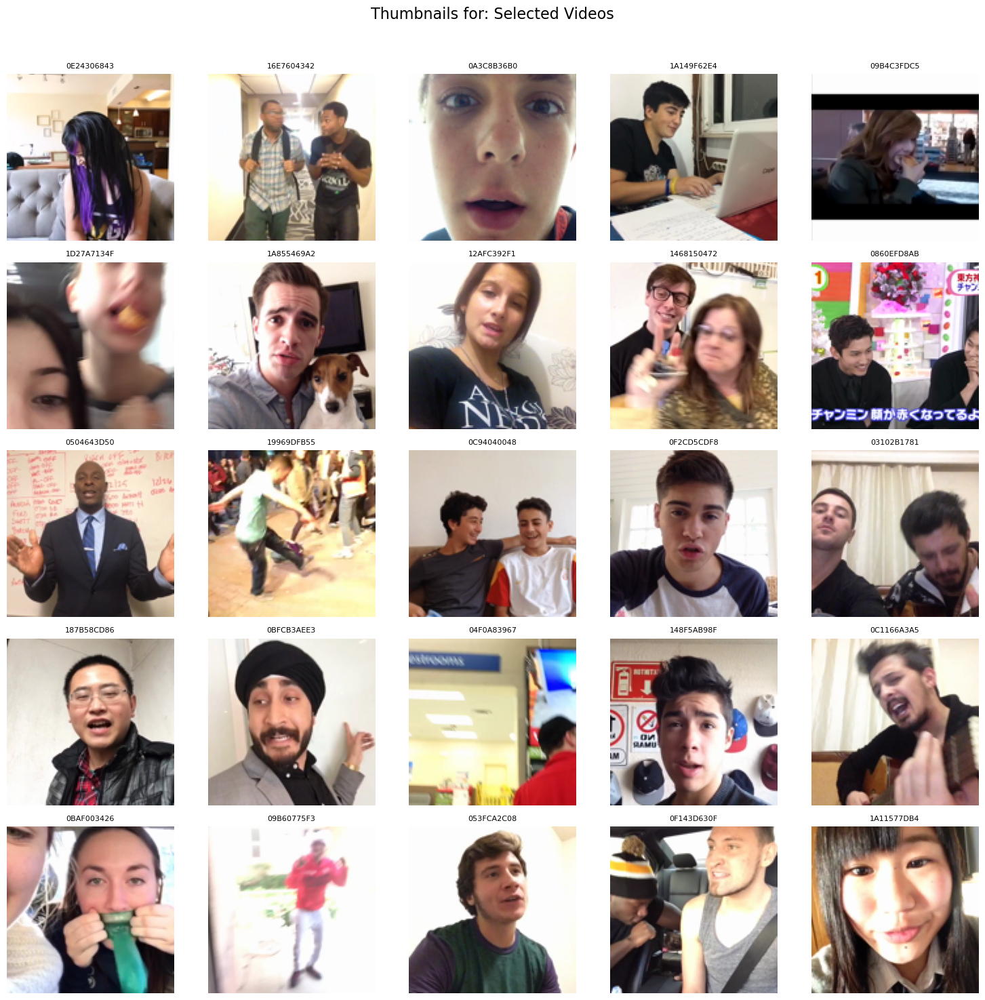

099D08E600 ************************************************************
✅ Found 25 nearest neighbors for 099D08E600.
['In the rain.', "This is WKZY and you're gonna die tonight. Is the title of this new song by Taylor Swift.", "So I'm going to pan him on next to me, bunch of my best friends Roger and Tony and me and no", 'That was a crit!', "19 Babe Babe, don't touch me!", None, "Sitting in on a jam. Don't look at me weird because I don't eat ham. It ain't my religion You won't find it in my kitchen. Stop your bitch and find out what you've been missing", "Well crap, it's just me myself. I asked out another girl got denied. I'm gonna be lonely for long.", "I'm your heart! Help me! How much longer are we there yet guys? Somebody help me! I'm not gonna miss the time!", 'We go on to number one rule at the mall. Fine daddy girl friend. Yeah, but be a good boy too.', 'Ah! Ah! Ah! Ah! Ah! Ah! Ah!', 'Cheers Cheers', 'I was pi- i was liking to Steven the- s- CDU Snap in a-', "You hear Megan so

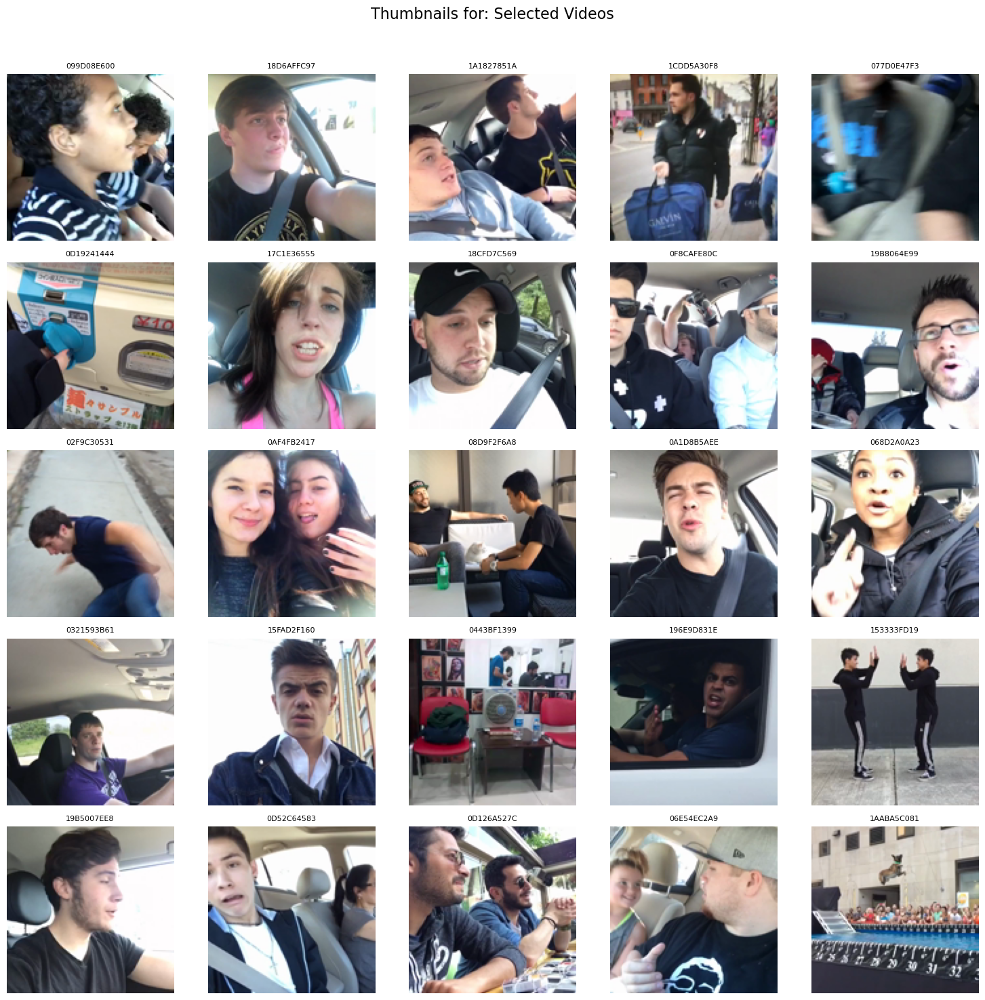

13395E89FC ************************************************************
✅ Found 25 nearest neighbors for 13395E89FC.
[None, "I'm going to go to the other side. Go ahead. Go ahead. Go ahead.", 'So, with all the time in it, you can see that', None, '', None, None, 'Think..', None, 'MOOOOO Get the fuck out of my way! HAHA', None, None, 'Hey, come on. Oh, my god. Yeah, man. Hey. Ah-ah.', '', 'Yummmmmmmmmmmmmmmmmmmmmmmm OK', None, "See you next time! We'll see you next time. Do-do-do, do-do do! We'll see you next time!", 'Was the maker told me the baby was mine? I laughed. Because he was a possum. He left the rest of it.', 'If the winning snapper was gauged on the size of its knob, this one would win hands down.', None, "We're recording owner of Mario Dad's Story for... That's good news What is this길шее intention of saying that in Gang Щın? Can I ask you a question? You,, before we take an interview oh yeah your, your question, please you ask him a question simply Does he still remember me?

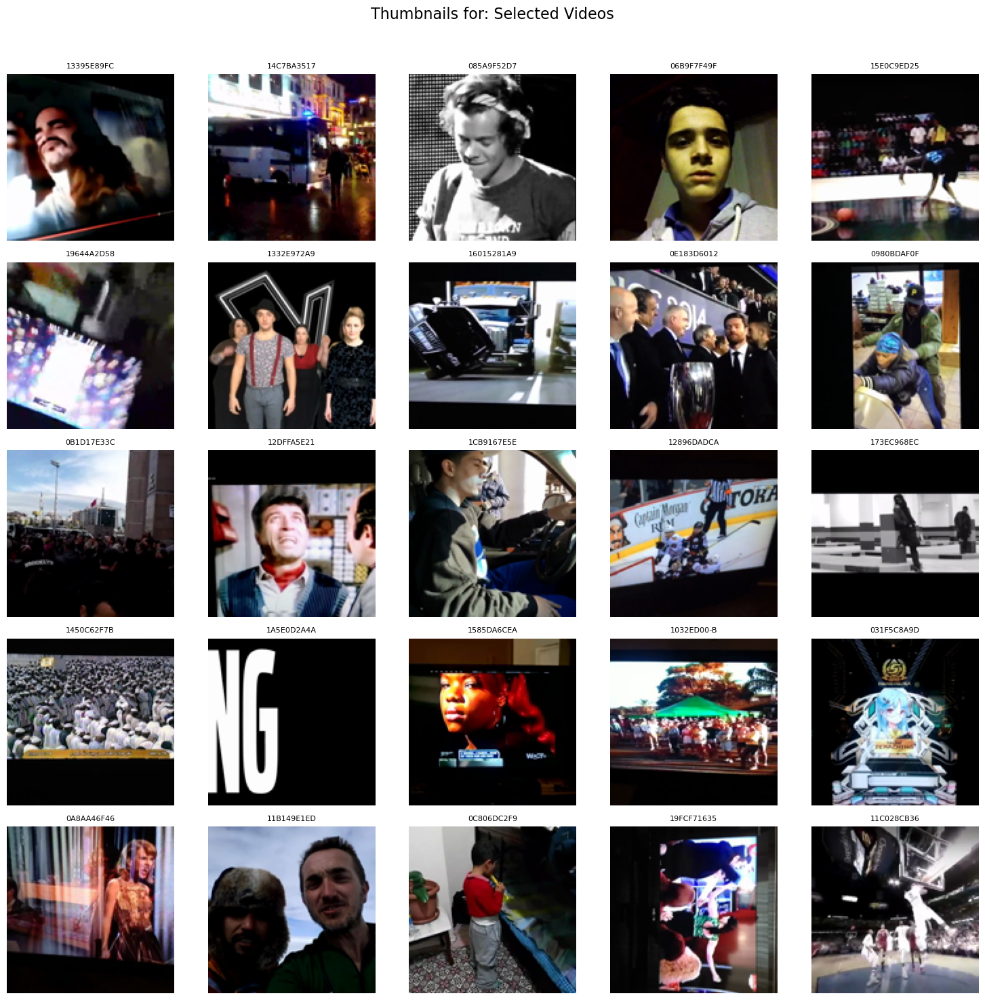

05B93B83F3 ************************************************************
✅ Found 25 nearest neighbors for 05B93B83F3.
["Yeah, yeah. It's in postcard. Is that a... It's in postcard. Is that a... Is that a...", "Don't you tell him what we do Don't talk, don't talk, you need to talk", "You're not good. Yes, we... You're not good. Oh my god. You're not good.", 'WELL! WELL! WELL! WELL! WELL! WELL! Yeah!', '', 'Grundlund Except for a carnival', "I'm not going to do anything. I'm not going to do anything. I'm not going to do anything.", None, None, None, 'I have to be leveled with this kind of thing. I have to be leveled with this kind of thing.', None, 'Really fake Sherlock', None, 'You have to love me if you have to love me.', 'Now, head and shoulders back to the ramp, scoop shot, sweep the floor out of bounds.', None, 'God Oops died oh', "I'm falling for the eyes, but they don't know me", 'One, two, three, two, one, four!', None, None, 'Boiled egg! Sit at theめり、すい Eat.', "all are falling do

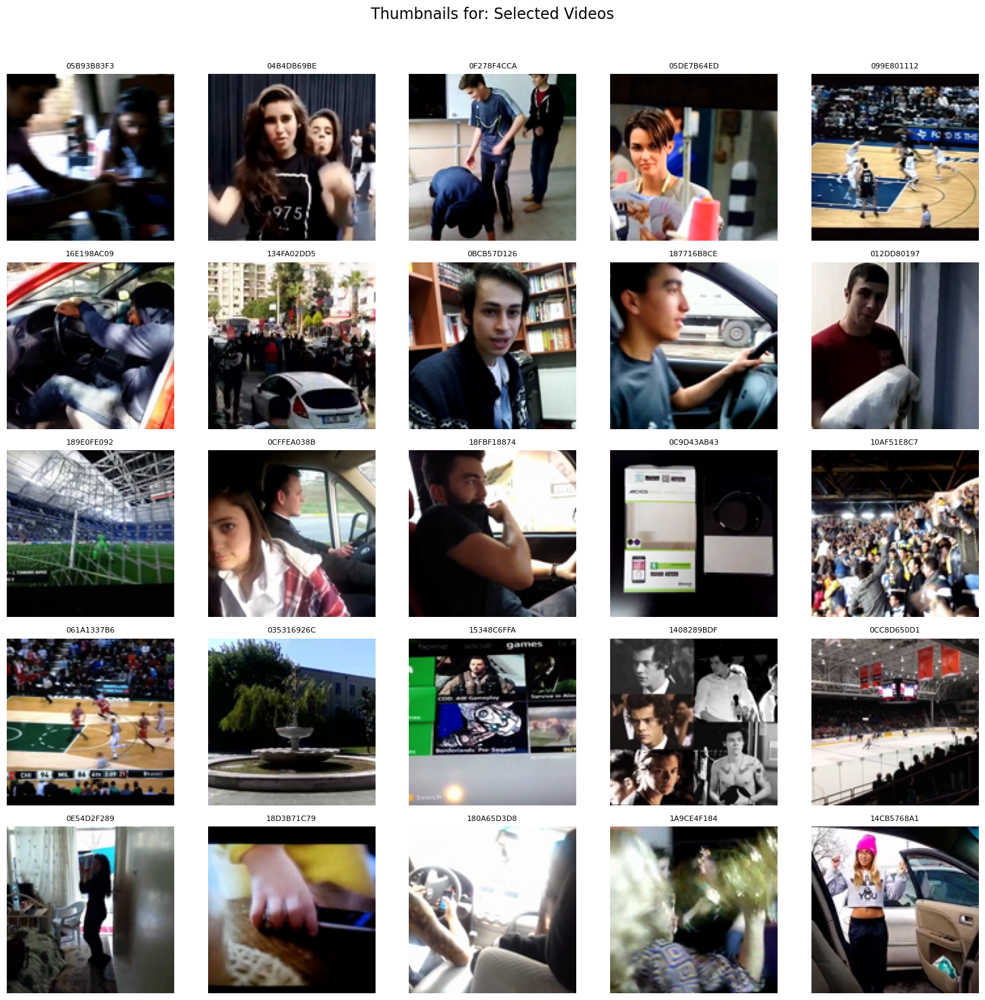

020B851B5F ************************************************************
✅ Found 25 nearest neighbors for 020B851B5F.
['Oh man, I love my beard. Oh come on man.', 'I look at training guys guys. Yeah, my god', "I'm gonna smash it to show you what she said. I'm gonna smash it to show you what she said.", '', "I was cleaning shop because I'm mad at you now", None, "Yo, from out into the baby, uh, what's your name? Let me turn to your make-bye", None, "Look. Damn. You're about to show me that rag? Yeah. Oh, come on. You owe me a new phone.", 'Oh', "Man is it me or Bletful can't keep no damn saw man. I don't know. I ain't got now. I'll talk about now", None, None, None, "Can I get some bread sticks? I don't know, can you? Mr. Whitney? Do you want the bread sticks? I think I'll pass. Also, now you try to pass something.", 'Honey, we got so poor! Yes, we got the sink and a mama!', 'Oh, what a mess. Someone should get on that mouth. You got some cleaning to do.', "I swear your hair looks good. 

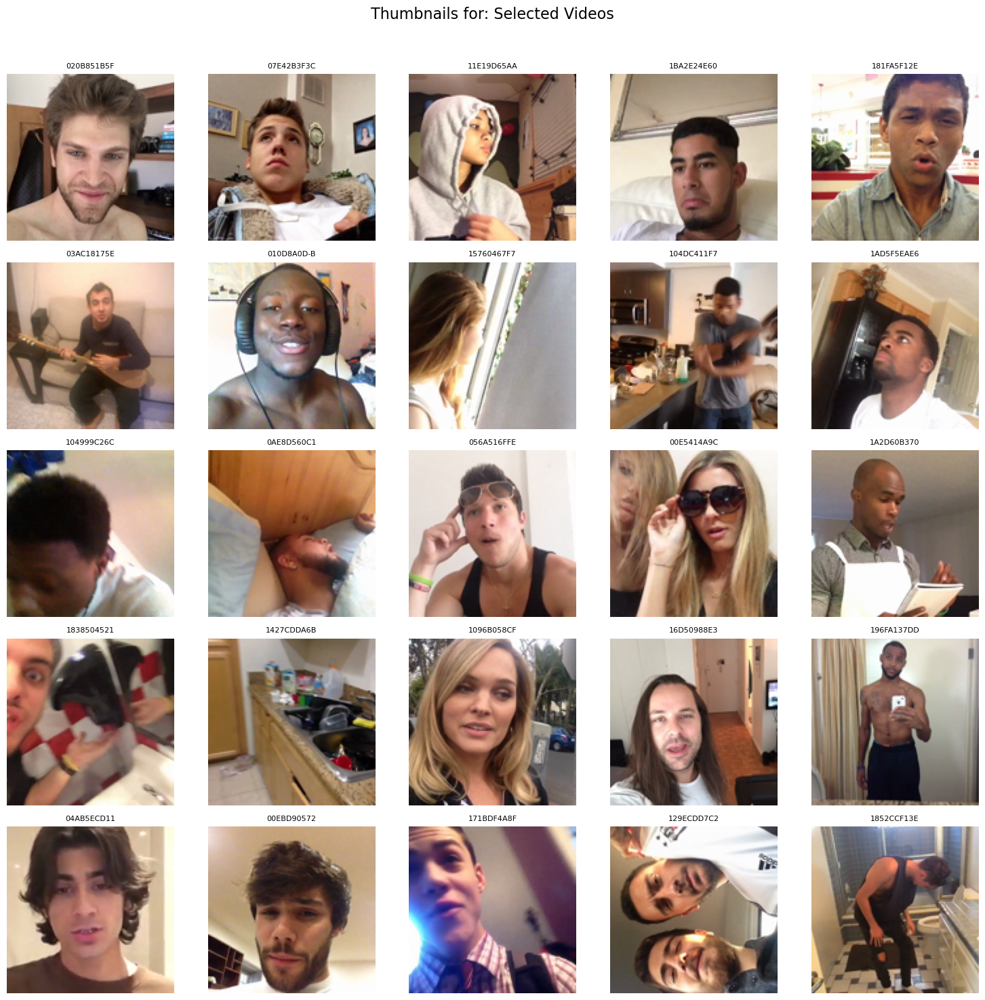

0F98A27AEA ************************************************************
✅ Found 25 nearest neighbors for 0F98A27AEA.
['', "Hey, you too, you too, I'm not gonna let you go You're not gonna let me go I'm not gonna let you go, you're not gonna let me go", "This summer's gonna be...", 'You are the matters to me, yeah, yeah', None, 'five', "Man, I'm scared of movies on the movie!", 'F&G Armedigue USA', None, 'rick', None, "Hi, not Britney Not oh this one's hot that one's hot", "I'm a song! This week's song...", 'I got you in my space I want you to move again', 'Music', None, 'NETWORK', 'Sure Finanz가 That is your unequal laughing run How the hell is that guy?', None, 'Oh, yeah', "He'll hit him so what's it mean? What's the? He's nothing. He's nothing.", "He scored on that one, he did that score on overtime, which the Warriors would probably prefer. He has to do in this game, and he doesn't...", '!!!', 'Raja, my left, hers look on my right. Two dudes.', 'What in the world did they remind you 

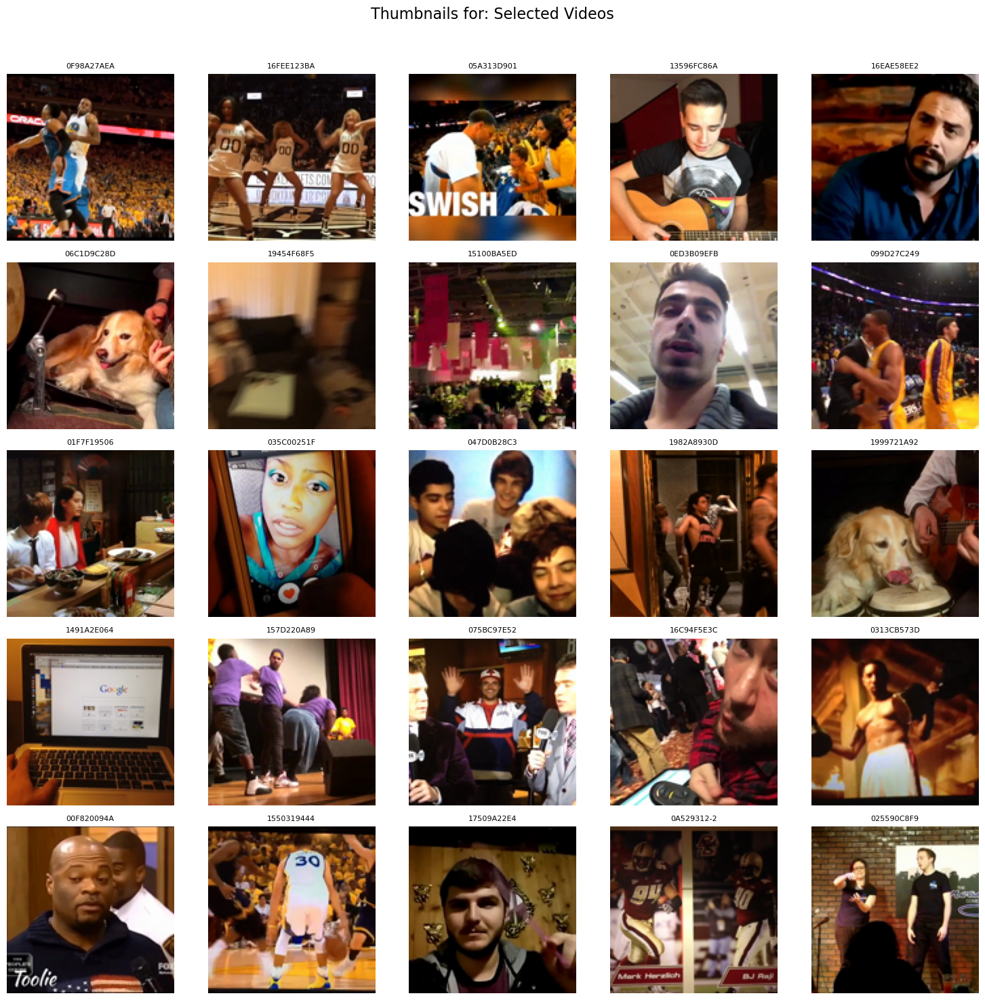

0F62B5FA70 ************************************************************
✅ Found 25 nearest neighbors for 0F62B5FA70.
['One girl, one girl! One girl, one girl! One girl, one girl!', '', None, 'V', 'ED', None, "I'll be here, I'll be here", 'As if.', 'Oh my god, sorkel! Here, take this. Felt fat!', "As I walk through the valley of the shadow I'll take a look at my life in real life", 'Please clap.', 'His protester was shoved to the ground by an officer. He appeared to be injured. He was later taken away in an ambulance.', "I'm going to get a car. I'm going to get a car. I'm going to get a car.", 'Immaya, immaa', 'Hey, look at this! On a truck! Turn on the truck! On a truck! And the bus is now on my side!', '', 'How much milk do I have to drink to be big enough to be quarter back?', '', "Hey! Hey! Say what you've got to say!", 'Oh', 'Hmmmain Co', "Oh yeah, I've got to change the TV for you. I'm gonna spider up there, I'll get it. Oh!", None, '', None]
📦 Found 25 IDs. Displaying first 25.


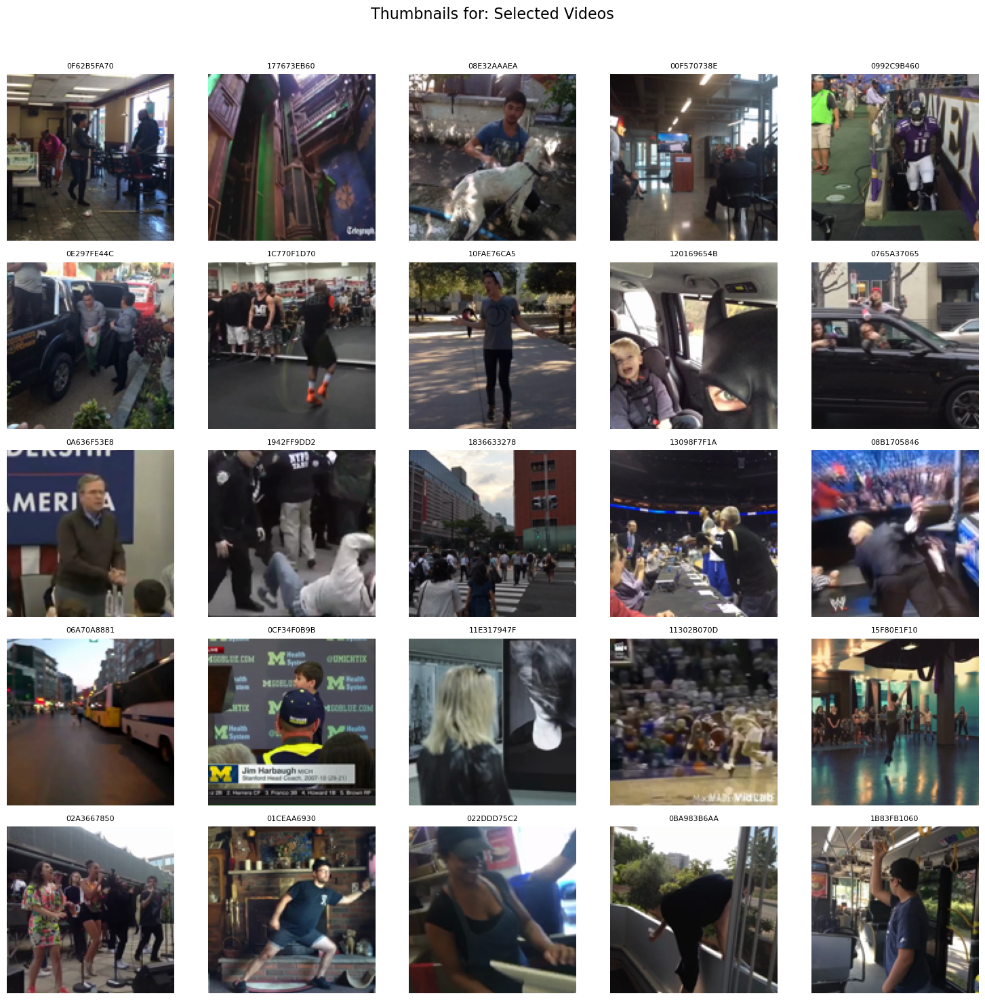

0EEA395110 ************************************************************
✅ Found 25 nearest neighbors for 0EEA395110.
["Spartan Reising on 3, got it! It's a left-down opportunity for a 4.5 play.", 'The Vice Crime Issue', None, "They're here to help usWd", 'Stand up. Rank up. Pass up. Rank up. Wake up.', None, 'She sent me the什么 related stuff Her name is Stan Takagatta', '', "Can I have all your money? I don't know, can you? Agh! Agh, I'll see you later!", None, None, "Don't die! I'll save it!", None, "His concrete will imp海 Hill's infinite Show me to his", 'Time to get groceries!', "that looks Paperwhy's not filming That was definitely Goverianild", None, None, None, '', "There's gonna get two tickets to go see FM. We're impressed. See FM live concert including flies.", 'Knock Knock, seems like no one knows where your Duck surrounded by everyone!', None, "We're not washing your hair.", "Man, I'm so hungry. Oh, I got some soup. Who the heck is Tom?"]
📦 Found 25 IDs. Displaying first 25.


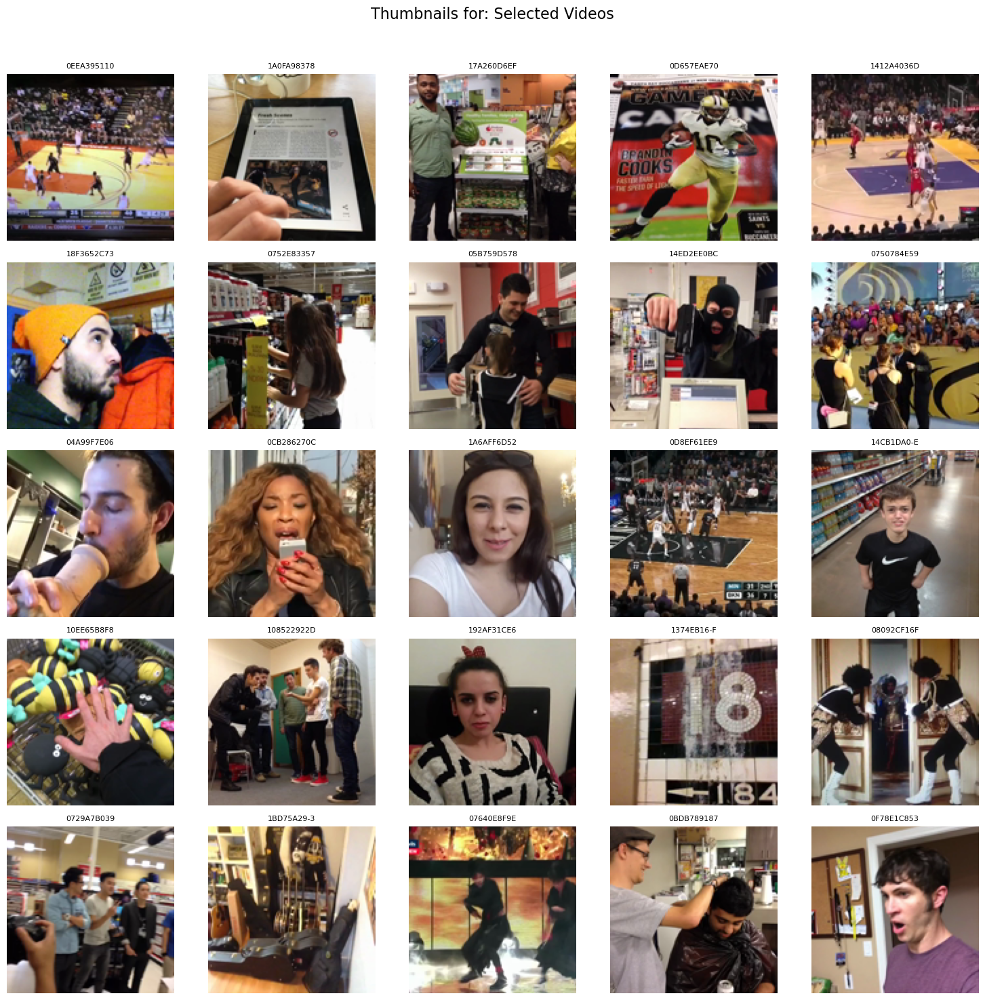

03431D33E3 ************************************************************
✅ Found 25 nearest neighbors for 03431D33E3.
["We gonna be patient in our neighborhood Because you got people to get your back over here You ain't alone like they are", None, "I'm not a footballer, I'm a junior I'm a junior I'm a junior I'm a junior I'm a junior I'm a junior", None, None, "Now when I'm in the road I'll be coming in a bit", None, 'Mom, what the fuck is mermaid? A mermaid? Yeah, mermaid a lot of money. Waaack!', 'Uhm, Oh! Get those guys!', "I just wondered how they can hit so many threes in a row and uh uh yeah there's something going on with his mouth here. Yeah, there's a lot of job.", 'Snapchat need to stop at an all-easy relevant as features and bring back best friends so I can see you having sex with who', '', "Yo, you remember that girl that had the clothes? That's just beyond it! Bro, she came over and that hair like... That's just me real!", 'A G shoot wit Rotę Im playing that IP遠 Im being áa

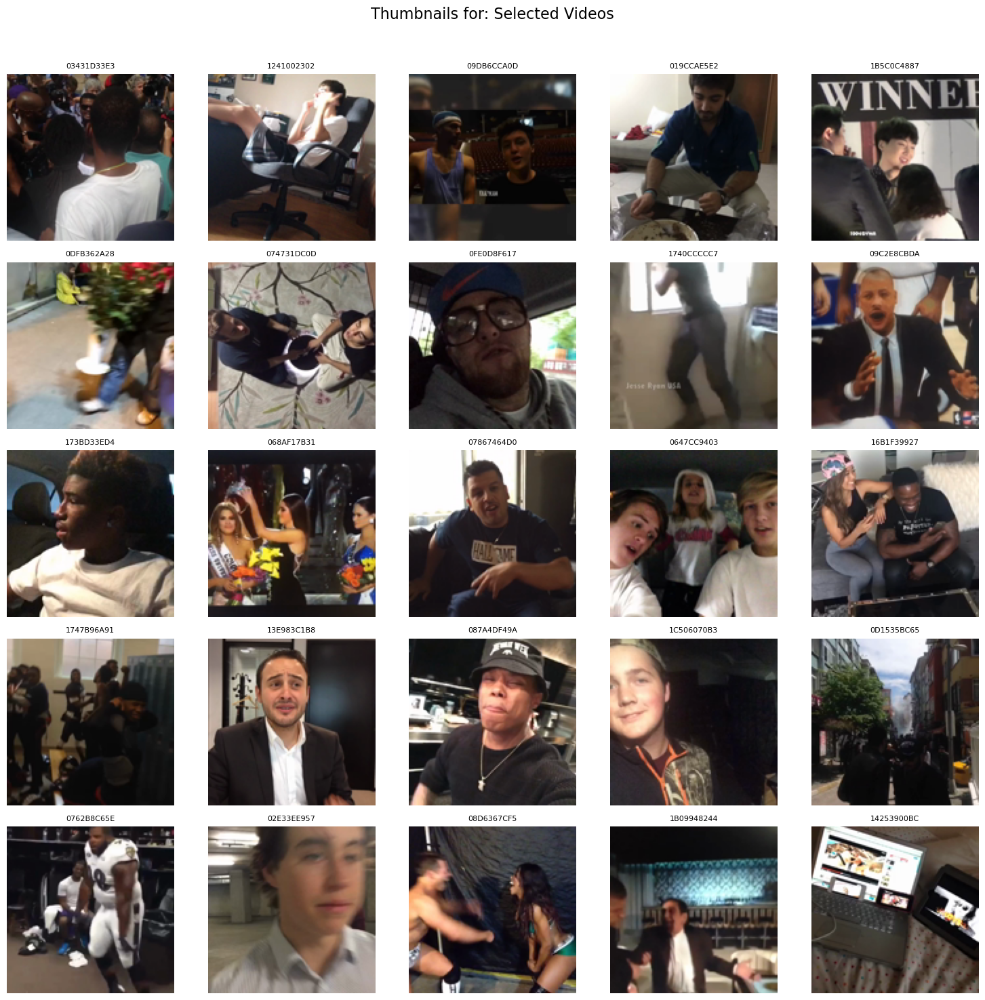

1386698107 ************************************************************
✅ Found 25 nearest neighbors for 1386698107.
['', 'anken', 'OOF', 'bu hell', 'Everything is gonna get better.', 'fellas', 'Bingo paper dingo ber with the dangolog', "let's get down the drain", 'Shit', None, "I wanna get you by yourself, yeah, I'll get to myself", "I'm not listening to you", "Justin Bieber's pop star Justin Bieber", 'Press break Wait Angels Poets Westcomace', 'Maybe tell you again', "Hey guys, it's Karen, and you enjoyed theρέ, thanks for coming today!", 'this GETS SO BARBING this又3acas i love you this part this ilaya h*** back full the loaS', 'mr.', 'you', "I'll make a say.", 'Good night and276', "I got the worst! I'm fat!", 'i forgot to say like', 'MY Bابin BABIE But the Lisa Devon carries', 'Is']
📦 Found 25 IDs. Displaying first 25.


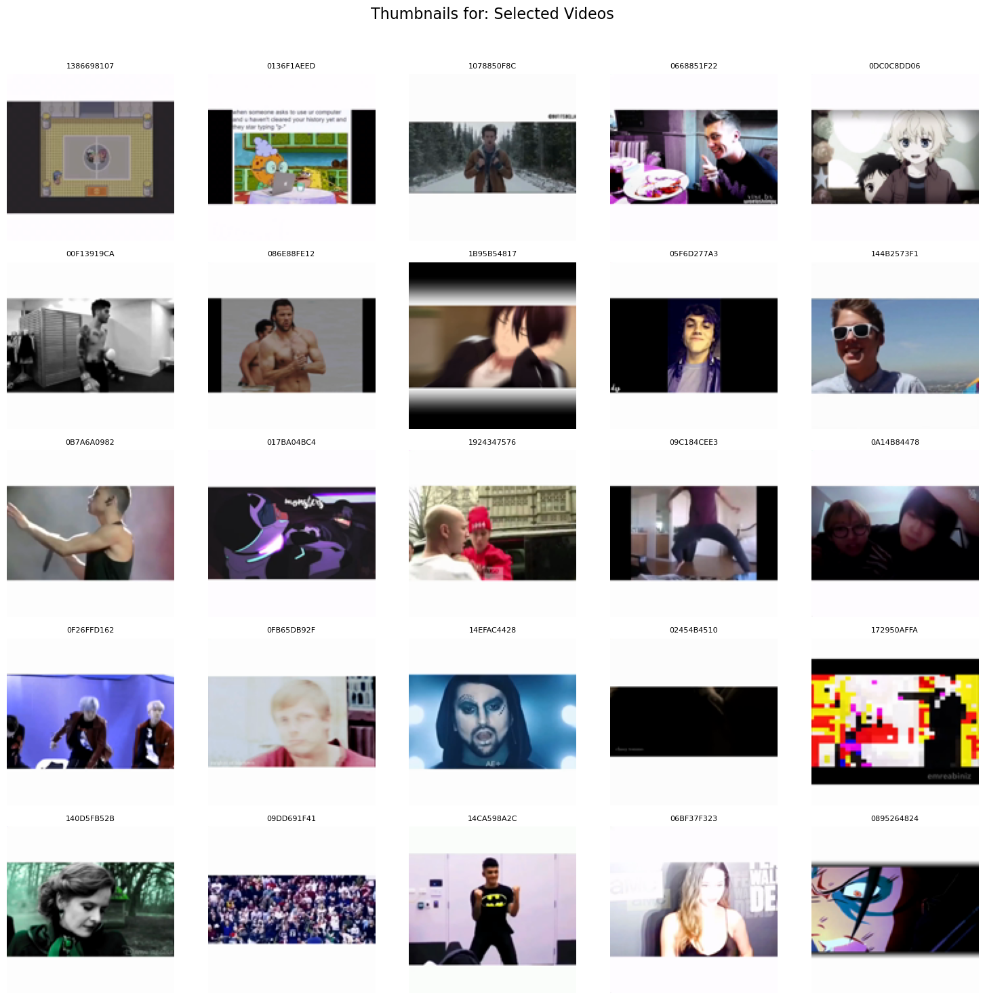

188B2007BD ************************************************************
✅ Found 25 nearest neighbors for 188B2007BD.
[None, None, "I'm so tired I'm so tired I'm so tired", "Some places what people might like in their lives Not about their destiny And I'll really find them What do you want ?", None, 'The circumference is hot. Is there a problem, Reggie?', "Good day sir, how are you feeling today? I'm pretty happy. Ah, so you're feeling gay? I'm a fucking gay dude!", 'èle', "It's a battle when all is the friend you make it's the road your trail", 'Oh', 'On the next avatar. skills.', 'So just to come in on my cell phone Lay night when I need you', None, 'So you told everyone what they need to bring to the party, right? Oh no, I accidentally told everyone to bring soda! Hey, God, I got this soda! Hey, God, I got this soda!', "And that's how we get the table tits. I love it, but what does it mean? So it's a tits? It's a tits on a table. Yes! Table tits!", 'Are you eating my fucking cookies?

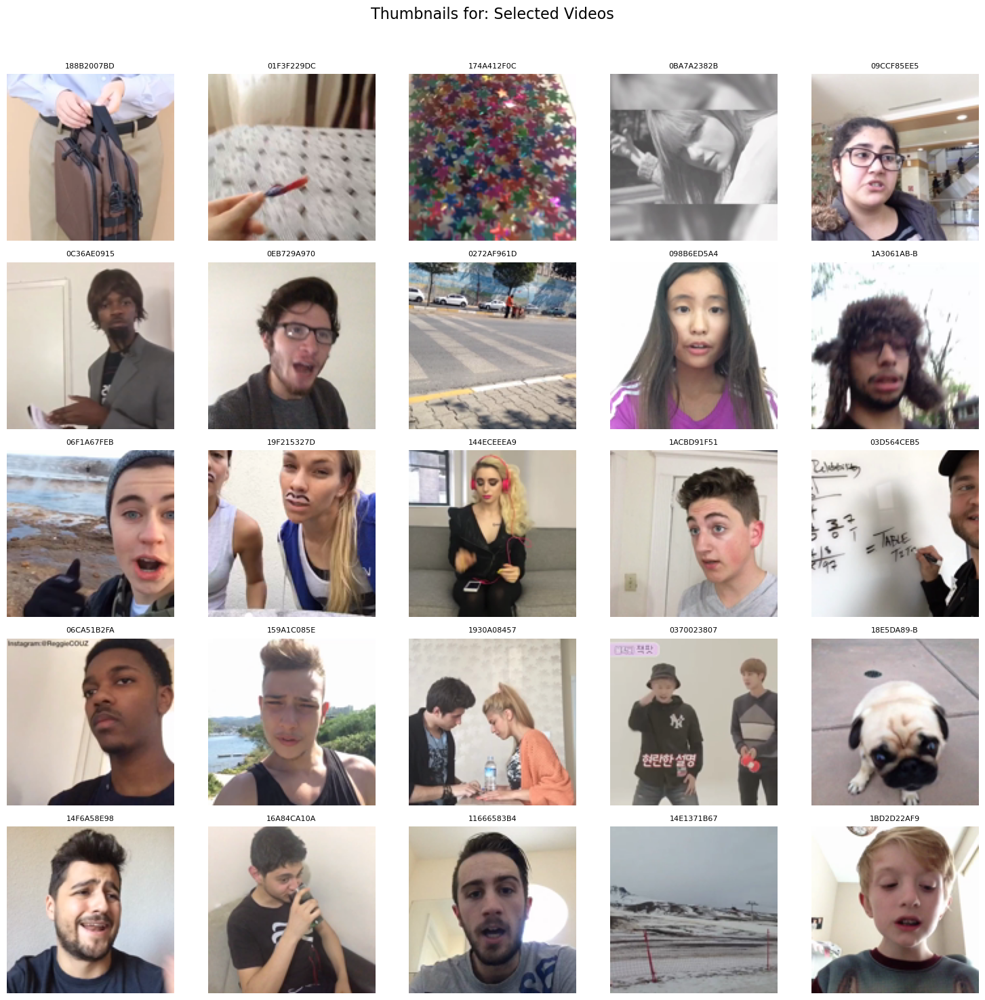

0ADEC2A861 ************************************************************
✅ Found 25 nearest neighbors for 0ADEC2A861.
['Please watch the second episode with this mysterious voice that appears in his fourth channel.', None, "If you don't get your monkey, see monkey, do build that on somewhere, crutch wreck top go next.", None, None, 'Rainbow', None, None, '', "We puns of the down your hair Don't give me that look be appreciate", "I'm so- AHHHHH It's getting hot in here What the fuck? Wait, I can't swim", None, None, 'You could waste a tank of gas trying to find a parking spot at Walmart.', '', 'Starting with the proposed', 'youngest', 'MARTED', "Story time! The man's butt scratching was complete. Dude, what? It was delightful. True. What?", 'BUM ASS LEGERO', None, 'Dance Dance It sounds rather rhythmical Exercise 6 Maximum Practice 7', None, "And I'll tell you all about it when I see you again.", '']
📦 Found 25 IDs. Displaying first 25.


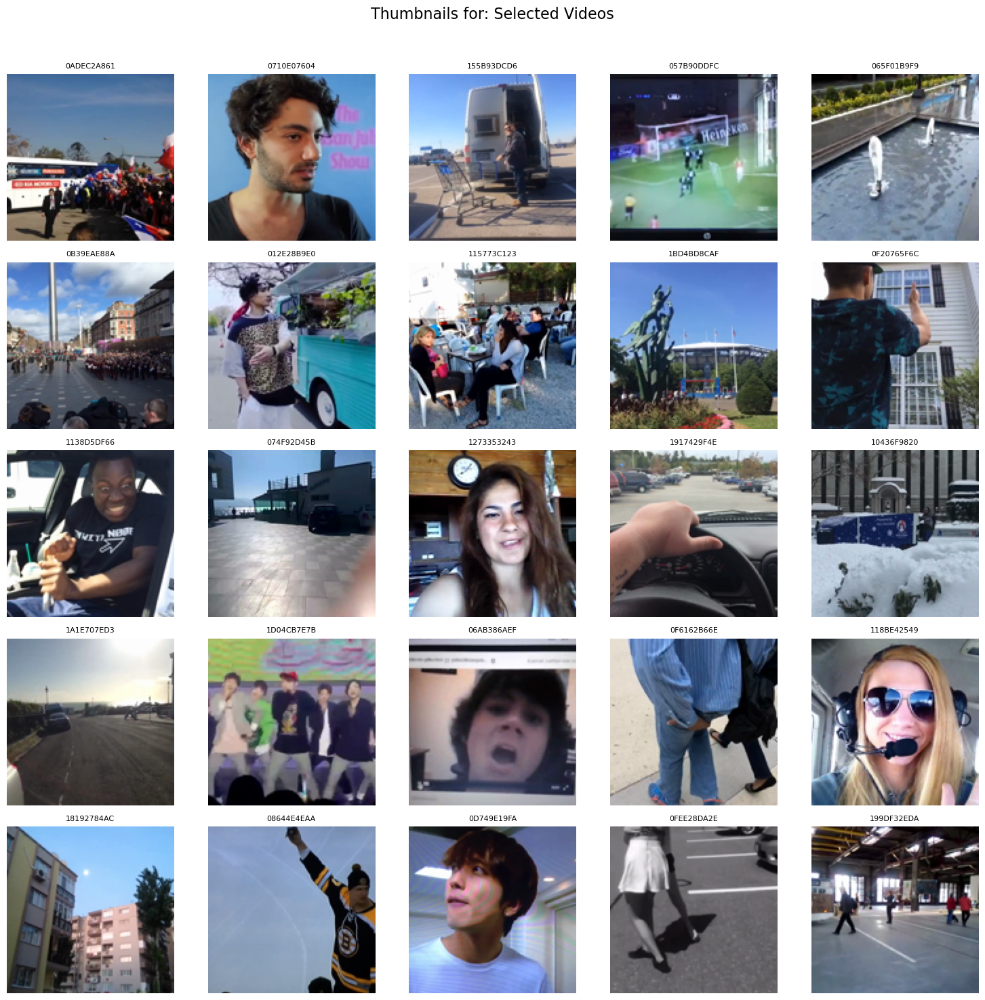

1C76BF33A4 ************************************************************
✅ Found 25 nearest neighbors for 1C76BF33A4.
['Bighai hai Mummy jama quién wah jame没不恋 hee Mon today hei is you', None, 'Good morning. Good morning. Good morning.', None, '...nig niggas bea frags OH! Shit, shit, shit, shit!', None, "I want to tattoo but I just don't know what to get just make sure it really means something to you I got it. Do you like?", None, None, "My baby don't mess around Because she loves me so And this I know for sure", None, '🎵', 'You program nigga fuck you did you fucking with King Kong and got shit on me', None, None, "Live long and don't stab yourself in your fucking hand.", "Hey, just wanted to say thank you so much for everyone who's been doing the song collab. You guys have come up with some really cool stuff.", None, None, "What's up guys the video where I get tased will be up tomorrow so stay tuned the extended video. I'm an Instagram", None, "Hey, is your driver on his pay? No, that

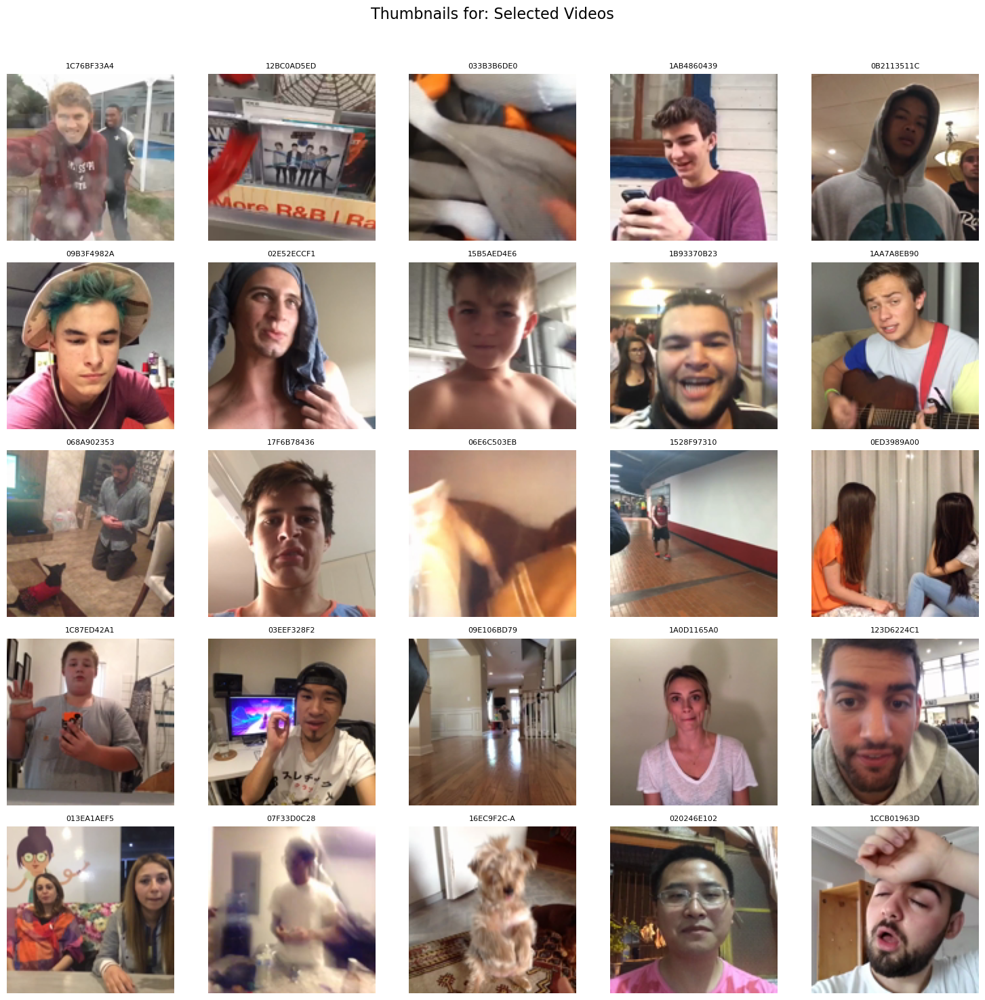

0E48FC2BB7 ************************************************************
✅ Found 25 nearest neighbors for 0E48FC2BB7.
["I'm only human And I question I break down", 'Sempre', "He's an ugly girl, spoke that one, that this are we're from", 'WILL PLEASE LEFT', None, 'Deep fire', None, "Say my name, cause those other men don't brag this This thing on time for a name, this thing on time for a game", "I got a second, it feels like I'm going mad I'm shaking a city like", None, 'Cut!', '1', "You don't know your beautiful, it's only you so what I can see is you understand", "I don't know what the fuck just happened, but I don't really care I'ma get the fuck about it, hey, it's shit, I'm not", "I'm a Luda. I'm a Luda. I'm a Luda.", 'so ah uh', 'lin', 'ieri application And ah Is you', 'Amount', 'wooo', "Don't always have to be happy and if you wanna cry, cry your fucking eyes out, do it!", "I'm too off, just under, I couldn't stop Just make that pussy pop Do it how I want it", '️', '', 'Jesus just

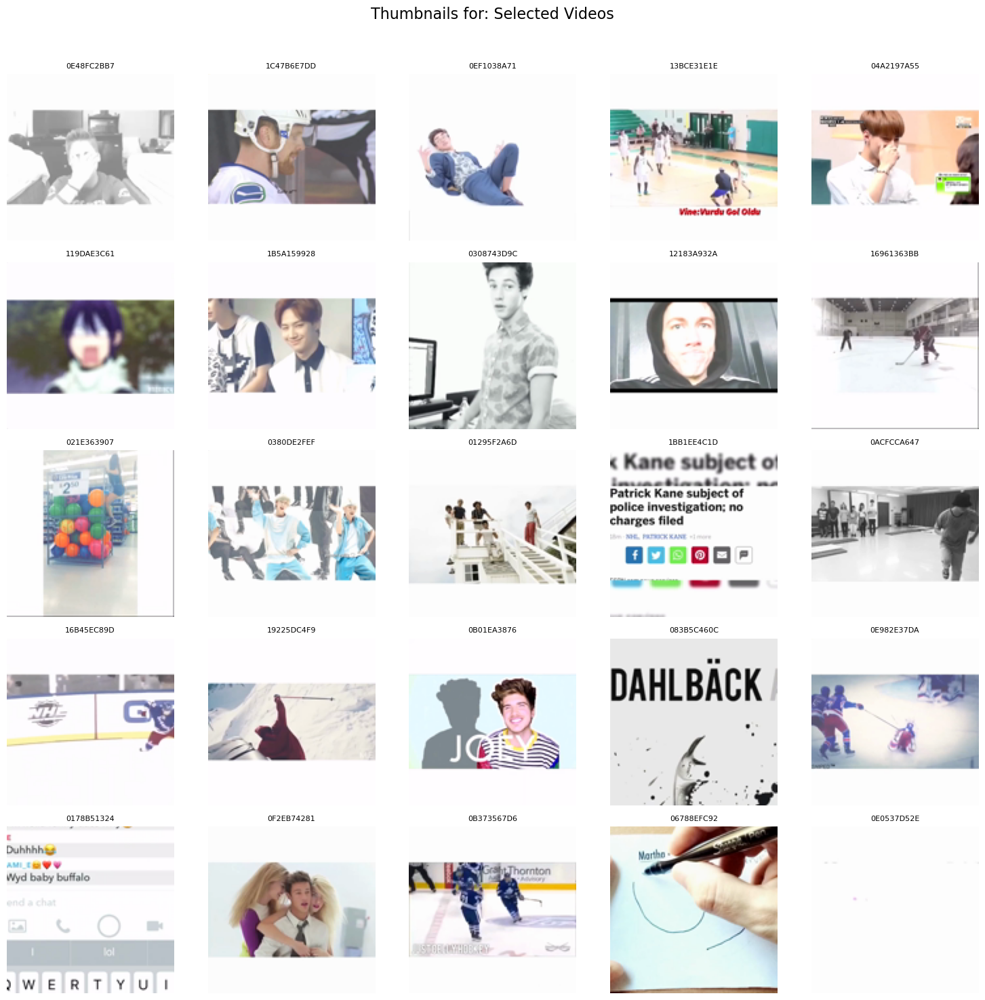

18CC03754C ************************************************************
✅ Found 25 nearest neighbors for 18CC03754C.
['Teamura', None, 'We speak our Zuckerberg so that they will speak our country.', None, None, "I'm gonna be a man, I'm gonna be a man, I'm gonna be a man, I'm gonna be a man...", None, "I'm gonna leave me honey, I'm your sweet trucker Can't even run like the winners all the way to bed", 'Hey, Baba, do you like the Miami Heat? Yes! Yes, Miami Heat Number One!', 'The last moments in civilization, how you feeling?', 'Wait The Night spool has gone spool bogaaaae And again', None, 'Thank you all.', None, "Bear cuz my god I believe it read why I'm blue If you criticize police, then you hate the troops", 'He was a punk, and she did ballet What more can I say?', '', '', 'No, no, no, no, no, no, no, no, no, no, stop it!', 'Condition', "And you'll get immersed in, all the water, you loh, all that love to him!", "And here's... ...stunned it down. One!", 'I will be married to my din

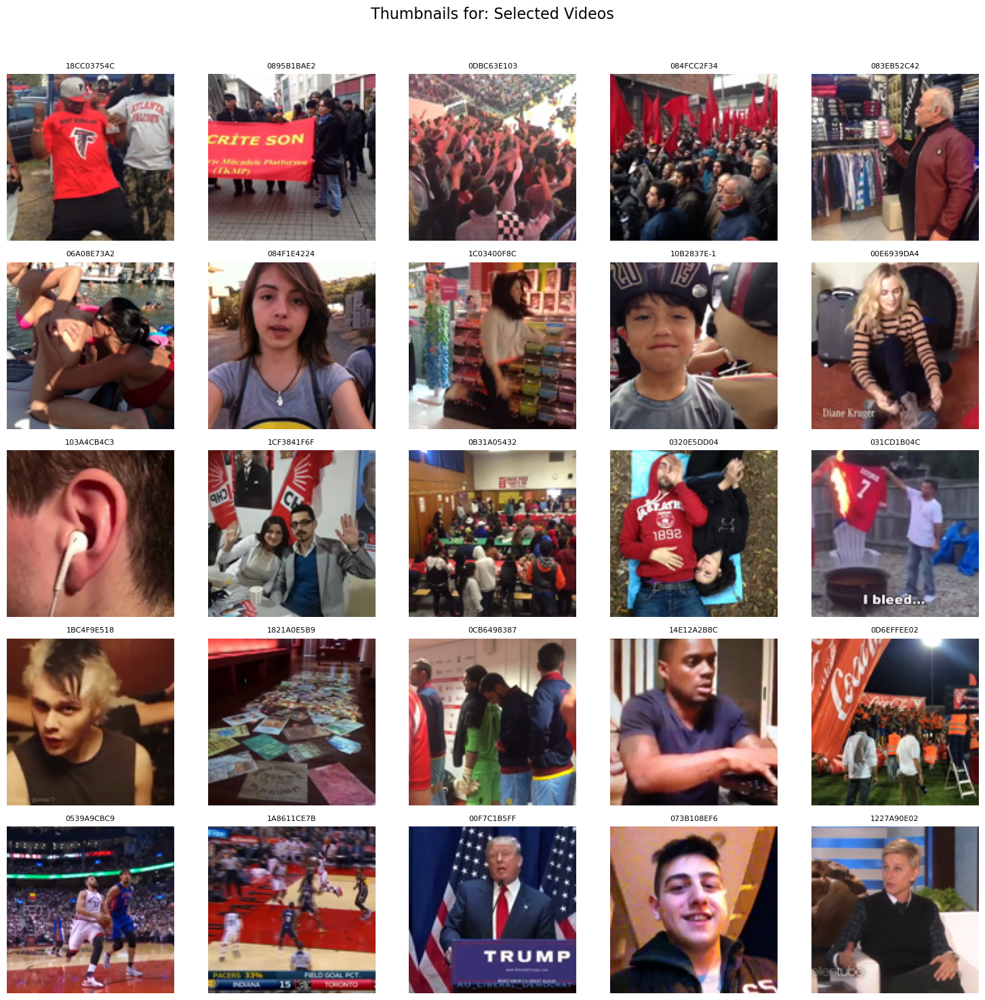

069CF71F5B ************************************************************
✅ Found 25 nearest neighbors for 069CF71F5B.
["I'm not a burden, not a way, I'm not a comic, I'm a movie", 'EVENT', 'God santé Lee this is my boyfriend', "It is the year's over. A friendship will never die.", None, None, "1hr sos OH CHkie 1980's experiments", 'Music', None, 'Un Clap Up', "Seems like you're just joking about me I'm notロ po t c th th th th th z", 'Yesterday, the city was wonderful. She made me feel young again.', "You're getting to be a big boy! I'm not gonna get smart each time you go!", 'And this is what I use to do And this is what I use to do And this is what I use to do', 'Trance', "I wanna paradise up Now I don't take a lot to make your wish", "I'm a fool for you", 'Toastuttaa-', '', "I wanna be forever Or stand and go down and stay in there If you don't, you wanna go to...", "Watch him rollin', watch him go! He be rolling down the street. He be rolling to the beat. He be rolling down the stree

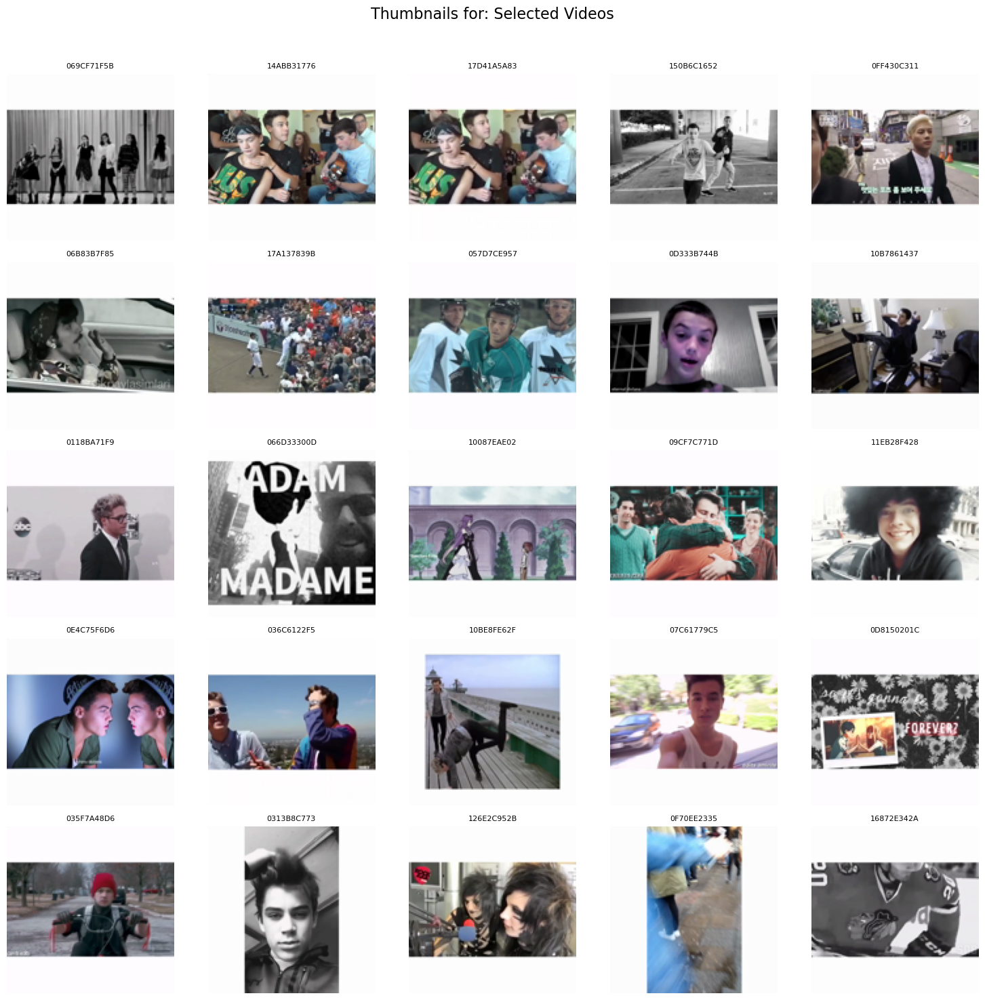

0A812A85AF ************************************************************
✅ Found 25 nearest neighbors for 0A812A85AF.
['We have a video header from K', 'blessing of the', None, '.', '', "This is WKZY and you're gonna die tonight. Is the title of this new song by Taylor Swift.", None, 'Hold on, let me just open my window. Oh, okay, okay.', "That's the kind of shit you see on me. No man. No bless you. No problem. God bless you man.", None, "I'll miss you.", "Yes, it's a save was your last day Of your friends, it's a save", None, 'In the rain.', "Check that down I'm trying to read I said I'm trying to read One fish", None, 'We go on to number one rule at the mall. Fine daddy girl friend. Yeah, but be a good boy too.', '', 'I gave my time with two or three knots that I put around for Oh, yes!', 'Cheers Cheers', '', None, 'That one you have to cross the street. Oh well, thank you young man. The emma feels good to be a good kid.', None, None]
📦 Found 25 IDs. Displaying first 25.


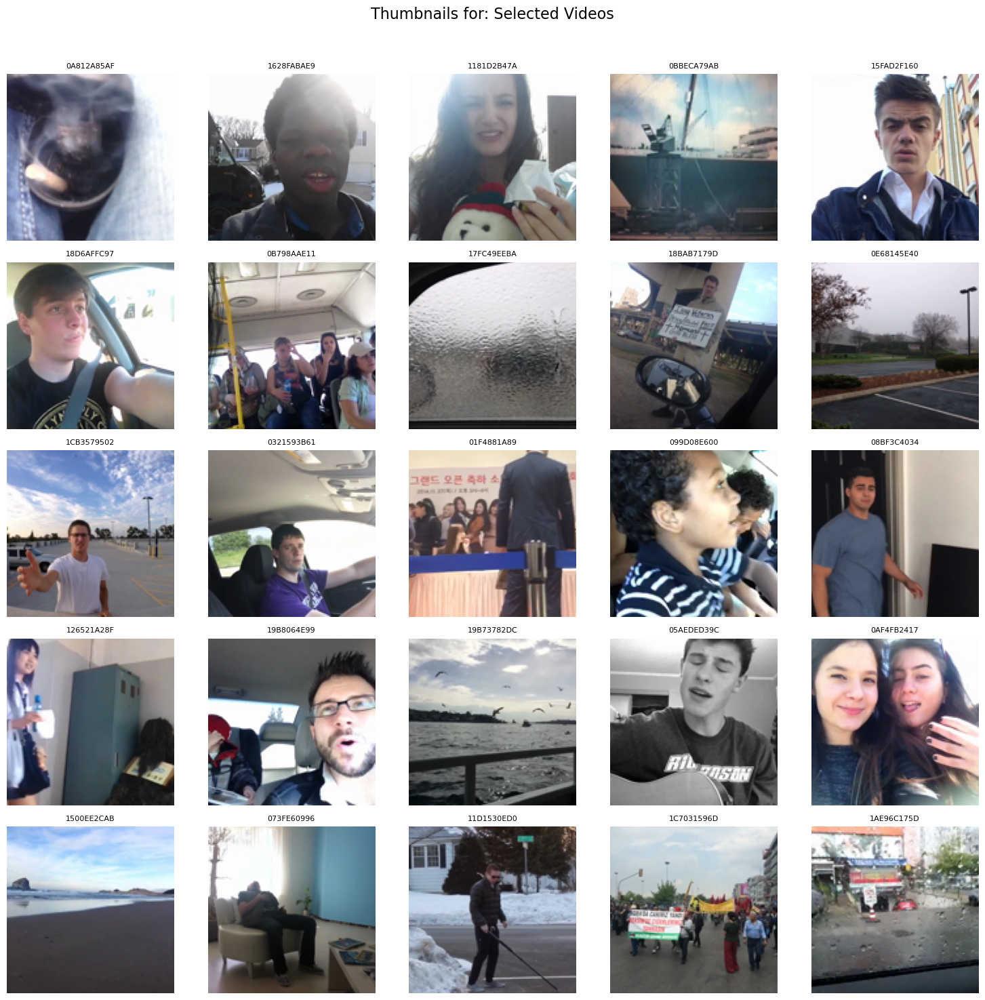

0C0C2FA21D ************************************************************
✅ Found 25 nearest neighbors for 0C0C2FA21D.
["We are the Goat Team Children in the game, we're going to time. We see we're going to stop. We hate.", 'We are the same', 'video', 'I intend to be your last.', 'iber Week�', "And I say hey, yeah, yeah, we're living like we're having cake", "And welcome to my house Baby, take control now We can't even...", 'Charlie did not go into the flag 5', 'And now EYES!', 'All the<|la|>', 'Uh, BTS and ARMY is..', 'Please Subscribe to new videos', 'Every time she closed her eyes', 'MUSIC', 'stars', "I really want you, you, you uhh Hit the clock for you, you-you Ice cave, all you do I know you'll do", 'People kill on people die and show them how you hear them crying. Can you practice what you breathe?', "We're gonna win My release We are rich We do everything you can", 'Oh', 'You got me like... Oh dear.', "I don't feel perfect at all Sad and insecure flaw Yeah", 'SUBSCRIBE', "Pitchad

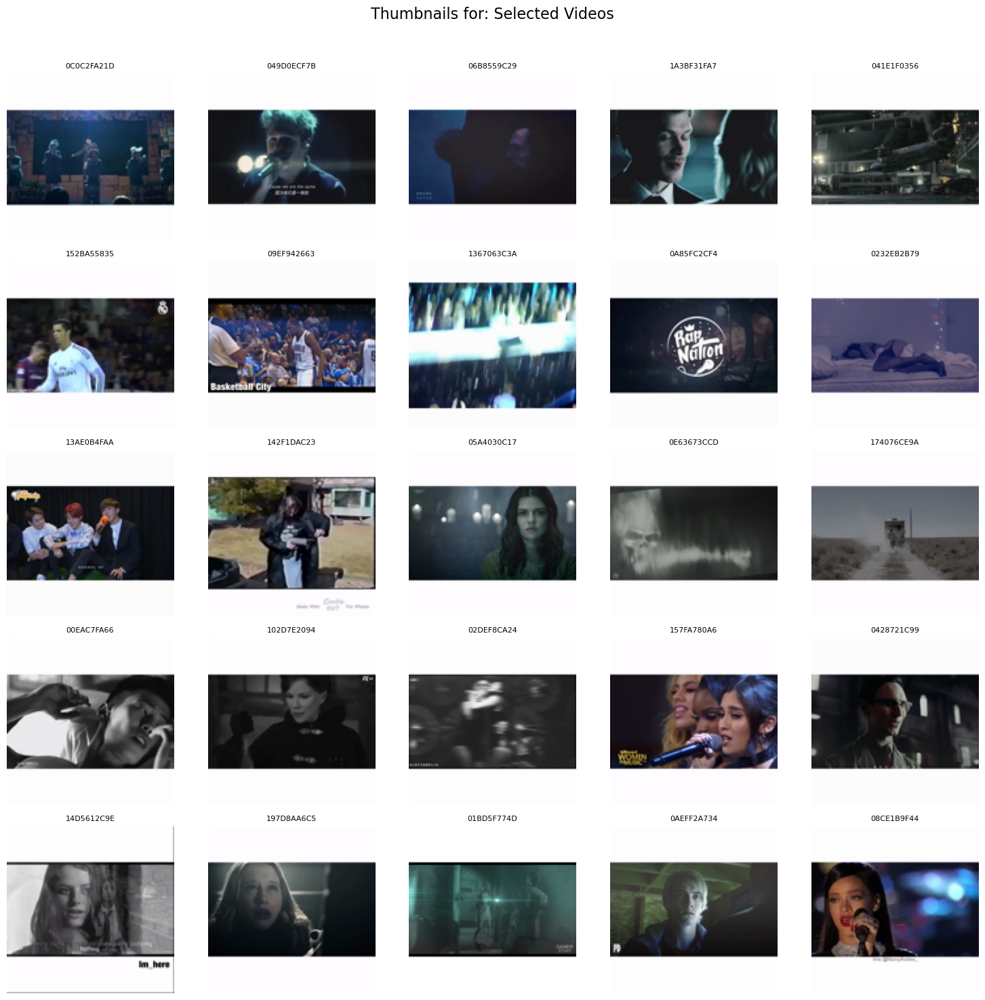

In [16]:
import random

for i in range(0,20):    
    rnum = int(28000*random.random())
    vid_id = list(df_data[rnum:rnum+1]["video_id_short"])[0]
    print(vid_id, "***"*20)
    rogers_hood = generate_nn_cluster(df_data,vid_id)
    print(list(rogers_hood["whisper_transcript"]))
    display_video_thumbnails(rogers_hood)
    

In [17]:
df_data

,filename,video_id_short,whisper_transcript,embedding
0,20130626125209_182352F6-CFF3-497C-9891-8FF7D18...,182352F6-C,All DOGROUND... ALL DOGROUND... Call ohmd,"[-0.031610012, 0.03581158, 0.031906445, 0.0145..."
1,20130627194331_18C3F6CB-6E8C-4DD1-A245-CCA4CF2...,18C3F6CB-6,"Baby, Baby!","[-0.02479268, 0.029688096, 0.028634664, 0.0226..."
2,20130628013622_14CF3EAD-D4F8-4174-885A-27A2D49...,14CF3EAD-D,How are you? Great Bob! We're all in a little ...,"[-0.015824113, 0.033187184, 0.01681333, 0.0065..."
3,20130628211747_18112C4B-742F-4745-ACB1-C76F89A...,18112C4B-7,,"[-0.024460625, 0.03128573, 0.0068606776, 0.033..."
4,20130702110757_0AC9933B-F979-4A43-BB29-89C0C05...,0AC9933B-F,None,"[-0.026678782, 0.03043931, 0.0365816, 0.024619..."
...,...,...,...,...
28334,20170120181149_02B098637B1406795882430660608_5...,02B098637B,So people are talking shit to me. Who's talkin...,"[-0.028940821, 0.032623377, 0.010157203, 0.024..."
28335,20170123151809_01E32E3DB41329092123169001472_1...,01E32E3DB4,You had a fool trying to see you You had a foo...,"[-0.0220203, 0.023668328, 0.0565179, 0.0142209..."
28336,20170123151814_01CC2625E61293428133021818880_3...,01CC2625E6,Everyway childhood,"[-0.02760518, 0.022845777, 0.038173363, 0.0173..."
28337,20170130004640_012C9A6F53968726164749381632_10...,012C9A6F53,Trademark by Mark. Everyone shut down and move...,"[-0.022903856, 0.026154868, 0.041475188, 0.023..."


In [18]:
pro_clip_seed = ["163720A9E3","19C72ED9DD"]#these can seed different images that are screenrecordings or phone shots of professional TV shows / clips
from_phone_footage = ["00EA9E6E85"]# these can seed different images actually shot live from a cell phone

# 06B58A644B #sports?

In [19]:
pro_ids = []
for p in pro_clip_seed:
    new_ids = generate_nn_cluster(df_data,p,50)
    pro_ids+=list(new_ids["video_id_short"])

print(pro_ids)

phone_footage_ids = []
for p in from_phone_footage:
    new_ids = generate_nn_cluster(df_data,p,100)
    phone_footage_ids+=list(new_ids["video_id_short"])
print(phone_footage_ids)#

✅ Found 50 nearest neighbors for 163720A9E3.
✅ Found 50 nearest neighbors for 19C72ED9DD.
['163720A9E3', '0FFB5305A8', '18743ADC78', '0AF4A397B1', '1040EFAC83', '1A5607D081', '1B600A4D55', '062F794558', '052727EDDC', '0BB7C5B71F', '13C8CFB464', '1958B4EDE8', '17604BCFA0', '1C5A5B51D1', '05556B405E', '02491092DC', '0D5F5ED47C', '1BAF6F668B', '15F38B499E', '07A3A6C577', '1CEEDC3D6B', '05F8BBDD05', '02FF24582F', '0E82F2EBDE', '056BEA19A0', '018BC37C75', '1A25EBB9CB', '03820CB0FD', '1BFD51A6B4', '1856AD1D70', '0A5E6C6A36', '0FC0DCDDED', '05B6178DF6', '1183490456', '11104014EB', '014A18596C', '118188B13E', '16D711B700', '183E2553DA', '00F8CAB1EB', '180C1BBBCF', '14BBBF3982', '058D581694', '116615348C', '00F794CA74', '10CD43AC53', '02A4037050', '0741AD065D', '0C7A9F047D', '168CD5A441', '19C72ED9DD', '156D244D19', '0815BDC7DD', '0BE5824418', '1221A9F055', '1A4FF9D530', '08414222DC', '0D91F3CF45', '0AC18996DE', '19CB53556D', '090318ADB3', '03B52E1375', '16FAD64E27', '0F9CCADA71', '069337B032',

In [20]:
import pandas as pd
import numpy as np
from typing import List, Union
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

def embedding_binary_classifier(
    data_df: pd.DataFrame,
    class_a_ids: List[str], 
    class_b_ids: List[str],
    id_column: str = "video_id_short", # ID column name
    embedding_column: str = "embedding"
) -> LogisticRegression:
    """
    Performs binary classification using the 'embedding' column as the only feature.

    Args:
        data_df: The DataFrame containing all video data and the 'embedding' column.
        class_a_ids: List of video IDs for Class A (Label 0).
        class_b_ids: List of video IDs for Class B (Label 1).
        id_column: The name of the column containing the video IDs.
        embedding_column: The name of the column containing the 768D feature vectors.

    Returns:
        A trained sklearn LogisticRegression model.
    """
    
    # 1. Prepare ID-to-Label Mapping
    
    # Create a Series mapping video_id_short to the class label (0 or 1)
    labels = {}
    for video_id in class_a_ids:
        labels[video_id] = 0
    for video_id in class_b_ids:
        labels[video_id] = 1

    # Filter the main DataFrame to only include videos in our defined classes
    all_ids = class_a_ids + class_b_ids
    filtered_df = data_df[data_df[id_column].isin(all_ids)].copy()
    
    if filtered_df.empty:
        raise ValueError("No matching video IDs found in the input DataFrame.")

    # 2. Extract Features (X) and Labels (y)
    
    # Convert the list-of-lists/arrays in the 'embedding' column into a 2D NumPy array
    try:
        X = np.stack(filtered_df[embedding_column].apply(np.array).to_numpy())
    except Exception as e:
        raise RuntimeError(f"Error converting embeddings to NumPy array. Check data type: {e}")

    # Map the IDs in the filtered DataFrame to their corresponding labels
    y = filtered_df[id_column].map(labels).to_numpy()
    
    if X.shape[1] != 768:
        print(f"Warning: Expected 768 dimensions, but found {X.shape[1]}.")

    print(f"Dataset ready: {X.shape[0]} samples, {X.shape[1]} features.")
    
    # 3. Train/Test Split
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    
    # 4. Train the Model
    
    model = LogisticRegression(random_state=42, max_iter=2000)
    model.fit(X_train, y_train)
    
    # 5. Evaluate and Print Score
    
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print("--- Training Complete ---")
    print(f"Test Set Accuracy: {accuracy:.4f}")
    
    return model

# --- Example Usage (Simulated Data) ---

# # Re-create a simulated DataFrame with the correct structure and list-like embeddings
# data = {
#     'filename': [f'file_{i}' for i in range(150)],
#     'video_id_short': [f'ID_{i}' for i in range(150)],
#     'whisper_transcript': ['transcript'] * 150,
#     # Simulate 768D embeddings: Class 0 shifted left, Class 1 shifted right
#     'embedding': [np.random.randn(768) - 0.5 if i < 75 else np.random.randn(768) + 0.5 for i in range(150)]
# }
# full_df = pd.DataFrame(data)

# Define the class IDs
# class_0_ids = [f'ID_{i}' for i in range(70)] # 70 IDs for class 0
# class_1_ids = [f'ID_{i}' for i in range(70, 140)] # 70 IDs for class 1 (shifted to ensure unique lists)
# class_0_ids = list(df_data[100:]["video_id_short"])
# class_1_ids = list(df_data[-100:]["video_id_short"])


class_0_ids = pro_ids
class_1_ids = phone_footage_ids


print("--- Starting Embedding Classification ---")
trained_model = embedding_binary_classifier(
    data_df=df_data, 
    class_a_ids=class_0_ids, 
    class_b_ids=class_1_ids
)

print(f"\nModel trained successfully. Features used: {trained_model.n_features_in_} dimensions.")

--- Starting Embedding Classification ---
Dataset ready: 200 samples, 768 features.
--- Training Complete ---
Test Set Accuracy: 1.0000

Model trained successfully. Features used: 768 dimensions.


In [21]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from typing import Tuple

def select_top_certain_predictions(
    model: LogisticRegression,
    data_df: pd.DataFrame,
    id_column: str = "video_id_short",
    embedding_column: str = "embedding",
    top_n: int = 500
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    Predicts probabilities for all videos and selects the top 'top_n' most
    certain for Class 0 and Class 1, based on probability scores.

    Args:
        model: The trained sklearn LogisticRegression model.
        data_df: The DataFrame containing all video data.
        id_column: The name of the column containing the video IDs.
        embedding_column: The name of the column containing the 768D feature vectors.
        top_n: The number of top most certain videos to select for each class.

    Returns:
        A tuple containing two DataFrames: (top_n_class_0_df, top_n_class_1_df).
    """
    
    # 1. Prepare Features (X) from the entire DataFrame
    
    # Check if the embedding column has been processed (list vs. numpy array)
    if isinstance(data_df[embedding_column].iloc[0], np.ndarray) or isinstance(data_df[embedding_column].iloc[0], list):
        try:
            # Convert list-like embeddings to a 2D NumPy array
            X_all = np.stack(data_df[embedding_column].apply(np.array).to_numpy())
        except Exception as e:
            raise RuntimeError(f"Error converting embeddings to NumPy array: {e}")
    else:
        # Assuming the embeddings are already in a NumPy array format if not list-like
        X_all = np.stack(data_df[embedding_column].to_numpy())
        
    print(f"Predicting on {X_all.shape[0]} total samples.")

    # 2. Get Prediction Probabilities
    # predict_proba returns a matrix where:
    # Column 0 = Probability of being Class 0 (P(y=0|X))
    # Column 1 = Probability of being Class 1 (P(y=1|X))
    probabilities = model.predict_proba(X_all)
    
    # 3. Add Probabilities to the DataFrame
    results_df = data_df.copy()
    results_df['prob_class_0'] = probabilities[:, 0]
    results_df['prob_class_1'] = probabilities[:, 1]
    
    # 4. Select Top N for Class 0 (Highest prob_class_0)
    # Sort in DESCENDING order (highest probability first)
    top_class_0_df = (
        results_df.sort_values(by='prob_class_0', ascending=False)
        .head(top_n)
    )
    
    # 5. Select Top N for Class 1 (Highest prob_class_1)
    # Sort in DESCENDING order (highest probability first)
    top_class_1_df = (
        results_df.sort_values(by='prob_class_1', ascending=False)
        .head(top_n)
    )
    
    print(f"Selected {len(top_class_0_df)} videos most certain for Class 0.")
    print(f"Selected {len(top_class_1_df)} videos most certain for Class 1.")
    
    return top_class_0_df, top_class_1_df

# --- Example Execution ---
# Note: This assumes you ran the previous function and have a 'full_df' and 'trained_model'

# Simulate a larger DataFrame (e.g., 5000 videos) for testing the top 500 selection
# We'll use the 'full_df' from the previous step but extend it for a larger test population
# test_data = {
#     'filename': [f'test_file_{i}' for i in range(5000)],
#     'video_id_short': [f'TEST_ID_{i}' for i in range(5000)],
#     'embedding': [np.random.randn(768) + np.random.uniform(-2, 2) for i in range(5000)] # random test embeddings
# }
# large_test_df = pd.DataFrame(test_data)

# Combine the training data and the test data into one 'big df'
# In a real scenario, you'd already have your 'big df' loaded.
# big_df = pd.concat([full_df, large_test_df], ignore_index=True)


print("--- Selecting Top 500 Most Certain Predictions ---")
top_0_df, top_1_df = select_top_certain_predictions(
    model=trained_model,
    data_df=df_data,
    top_n=500
)

print("\n--- Summary of Top Class 0 Selection ---")
print(f"Highest certainty score (Prob Class 0): {top_0_df['prob_class_0'].max():.4f}")
print(top_0_df[['video_id_short', 'prob_class_0', 'prob_class_1']].head())

print("\n--- Summary of Top Class 1 Selection ---")
print(f"Highest certainty score (Prob Class 1): {top_1_df['prob_class_1'].max():.4f}")
print(top_1_df[['video_id_short', 'prob_class_0', 'prob_class_1']].head())

--- Selecting Top 500 Most Certain Predictions ---
Predicting on 28339 total samples.
Selected 500 videos most certain for Class 0.
Selected 500 videos most certain for Class 1.

--- Summary of Top Class 0 Selection ---
Highest certainty score (Prob Class 0): 0.9500
      video_id_short  prob_class_0  prob_class_1
9982      10CA8AB86F      0.949992      0.050008
2890      0E50A67CE2      0.948068      0.051932
17099     0D3D8B02ED      0.946707      0.053293
2110      117480ECA5      0.946011      0.053989
28201     01220A0AB6      0.945738      0.054262

--- Summary of Top Class 1 Selection ---
Highest certainty score (Prob Class 1): 0.8991
      video_id_short  prob_class_0  prob_class_1
12172     0DDA7ED289      0.100949      0.899051
24309     125B1B2298      0.105017      0.894983
4102      10F0FE61E0      0.108982      0.891018
14780     1D0E135437      0.109090      0.890910
11730     06026FA7FC      0.113024      0.886976


In [22]:
#class_0_ids = pro_ids
#class_1_ids = phone_footage_ids

📦 Found 500 IDs. Displaying first 50.


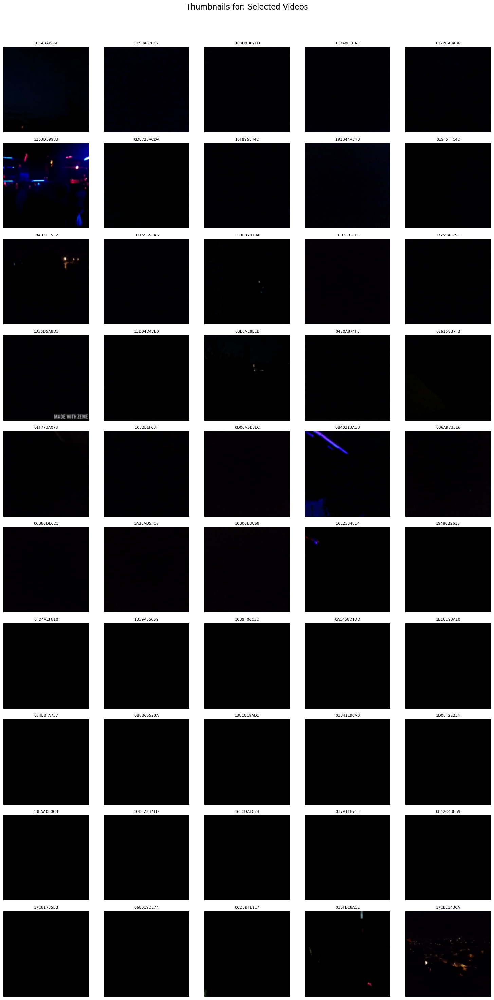

In [23]:
#pro shots looking at TVs
display_video_thumbnails(top_0_df,50)

📦 Found 500 IDs. Displaying first 50.


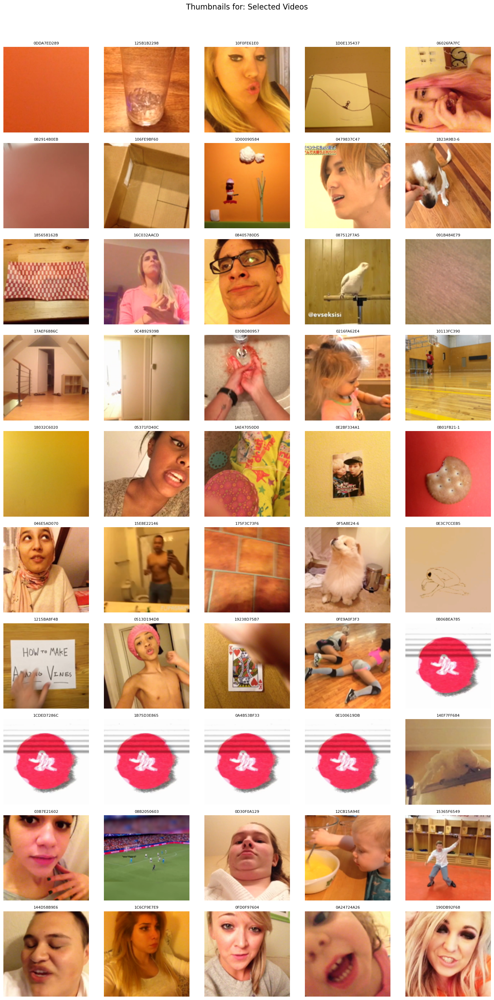

In [24]:
#from cell phone camera
display_video_thumbnails(top_1_df,50)

In [25]:
dfnn2 = generate_nn_cluster(df_data,"09A000E490")
# display_video_thumbnails(dfnn2)

✅ Found 25 nearest neighbors for 09A000E490.


In [26]:
dfnn2 = generate_nn_cluster(df_data,"09A000E490")
# display_video_thumbnails(dfnn2)

✅ Found 25 nearest neighbors for 09A000E490.


In [27]:
dfnn2 = generate_nn_cluster(df_data,"09A000E490")
# display_video_thumbnails(dfnn2)

✅ Found 25 nearest neighbors for 09A000E490.
